# Predviđanje revizorskog mišljenja za javna preduzeća u FBiH
# Audit opinion prediction for public enterprises in FBiH

Ulaz: bilansne pozicije (t i t-1). Cilj: `cilj_binarno` (1 = pozitivno + s rezervom, 0 = negativno + suzdržavanje).
Kolone nakon "Osnov za mišljenje" (Beneish omjeri, M-score, 0/1 oznake) **nisu** uključene.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.stats import pearsonr, spearmanr, pointbiserialr, chi2_contingency, skew, kurtosis

from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold, cross_validate
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, matthews_corrcoef,
                             average_precision_score, ConfusionMatrixDisplay)
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("XGBoost nije instaliran (pip install xgboost) - preskače se.")

sns.set_theme(style='whitegrid')
RS = 42

## Dataset loading - učitavanje dataseta

In [2]:
df = pd.read_csv('data/dataset_revizija.csv') 

## Display info about data and first five rows - prikaz informacija o datasetu i prvih 5 redova

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 29 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID_preduzeca            312 non-null    object 
 1   Sektor                  312 non-null    object 
 2   Godina_izvjestaja       312 non-null    int64  
 3   potrazivanja_kupci_t    312 non-null    int64  
 4   prihod_prodaja_t        312 non-null    int64  
 5   potrazivanja_kupci_t1   312 non-null    int64  
 6   prihod_prodaja_t1       312 non-null    int64  
 7   poslovni_rashodi_t1     312 non-null    int64  
 8   poslovni_rashodi_t      312 non-null    int64  
 9   obrtna_imovina_t        312 non-null    int64  
 10  nekretnine_oprema_t     312 non-null    int64  
 11  kratk_fin_plasmani_t    312 non-null    int64  
 12  poslovna_imovina_t      312 non-null    int64  
 13  obrtna_imovina_t1       312 non-null    int64  
 14  nekretnine_oprema_t1    312 non-null    in

In [4]:
df.head()

,ID_preduzeca,Sektor,Godina_izvjestaja,potrazivanja_kupci_t,prihod_prodaja_t,potrazivanja_kupci_t1,prihod_prodaja_t1,poslovni_rashodi_t1,poslovni_rashodi_t,obrtna_imovina_t,...,admin_rashodi_t,admin_rashodi_t1,kratk_obaveze_t,dugor_obaveze_t,kratk_obaveze_t1,dugor_obaveze_t1,novcani_tok_poslovni_t,misljenje,cilj_binarno,cilj_3klase
0,P001,Saobraćaj i infrastruktura,2018,1569973,34564122,2616396,36116977,45061690,43346981,13818573,...,29718683,31568284,225902690,0,215699458,0,-13704996.0,Negativno mišljenje,0,2
1,P002,Energetika i rudarstvo,2018,1737302,98336465,7469401,104563987,115511122,118848833,29156474,...,63494948,65316748,231694960,50518921,215908909,51300250,-22088244.0,Negativno mišljenje,0,2
2,P002,Energetika i rudarstvo,2018,2968910,67346322,3082738,80447397,77801891,79173988,9709508,...,46690135,47987133,108713252,10029776,103778117,10018683,8137240.0,Negativno mišljenje,0,2
3,P002,Energetika i rudarstvo,2018,1226574,12202060,1131792,12645798,13914208,14072426,3261233,...,9513606,9508934,39090700,471429,34384033,550000,3729683.0,Negativno mišljenje,0,2
4,P003,Komunalne djelatnosti,2018,721617,2064254,719155,2294813,2291551,2119059,1536103,...,1098925,1101113,1094978,0,815974,0,354760.0,Mišljenje s rezervom,1,1


## Displaying the number of missing values - broj nedostajućih vrijednosti

In [5]:
print(df.isnull().sum()[df.isnull().sum() > 0])

novcani_tok_poslovni_t    2
dtype: int64


Jedine nedostajuće vrijednosti su 2 u `novcani_tok_poslovni_t`; popunjavaju se imputacijom. Godina je kompletna: za 4 izvještaja čiji naziv ne sadrži godinu postavljena je vrijednost 2020, pa nijedan red nije izgubljen.

The only missing values are 2 in operating cash flow (imputed). Report year is complete: 4 reports without a year in the name were set to 2020, so no rows are lost.

## Defining variable groups - definisanje grupa varijabli

In [6]:
meta_kolone = ['ID_preduzeca', 'Sektor', 'Godina_izvjestaja']
ciljne_kolone = ['misljenje', 'cilj_binarno', 'cilj_3klase']
numericke = [c for c in df.columns if c not in meta_kolone + ciljne_kolone]
print(len(numericke), "ulaznih numeričkih varijabli:")
print(numericke)

23 ulaznih numeričkih varijabli:
['potrazivanja_kupci_t', 'prihod_prodaja_t', 'potrazivanja_kupci_t1', 'prihod_prodaja_t1', 'poslovni_rashodi_t1', 'poslovni_rashodi_t', 'obrtna_imovina_t', 'nekretnine_oprema_t', 'kratk_fin_plasmani_t', 'poslovna_imovina_t', 'obrtna_imovina_t1', 'nekretnine_oprema_t1', 'kratk_fin_plasmani_t1', 'poslovna_imovina_t1', 'amortizacija_t1', 'amortizacija_t', 'admin_rashodi_t', 'admin_rashodi_t1', 'kratk_obaveze_t', 'dugor_obaveze_t', 'kratk_obaveze_t1', 'dugor_obaveze_t1', 'novcani_tok_poslovni_t']


`ID_preduzeca`, `Sektor` i `Godina_izvjestaja` **nisu** ulazne varijable osnovnog modela: ID služi samo za validaciju po preduzećima, godina za vremenski test, a sektor se testira kao dodatak (vidi kasnije).

## Data cleaning - čišćenje podataka
### Impossible zero values treated as missing / Nemoguće nule tretirane kao nedostajuće vrijednosti
Preduzeće ne može imati nekretnine/opremu ili amortizaciju jednaku 0 u obje godine istovremeno dok drugu poziciju ima; takvi unosi se tretiraju kao greška i postavljaju na NaN (popunjava ih imputer unutar pipeline-a).

In [8]:
par = [('nekretnine_oprema_t', 'nekretnine_oprema_t1'), ('amortizacija_t', 'amortizacija_t1')]
for a, b in par:
    maska = (df[a] == 0) & (df[b] == 0)
    print(f"{a}/{b}: sumnjivih redova = {int(maska.sum())}", df.loc[maska, 'ID_preduzeca'].tolist())
    df.loc[maska, [a, b]] = np.nan
print("\nNedostajuće vrijednosti nakon čišćenja:")
print(df[numericke].isnull().sum()[df[numericke].isnull().sum() > 0])
print("Broj redova:", len(df))

nekretnine_oprema_t/nekretnine_oprema_t1: sumnjivih redova = 0 []
amortizacija_t/amortizacija_t1: sumnjivih redova = 0 []

Nedostajuće vrijednosti nakon čišćenja:
nekretnine_oprema_t       1
nekretnine_oprema_t1      1
amortizacija_t1           1
amortizacija_t            1
novcani_tok_poslovni_t    2
dtype: int64
Broj redova: 312


## Target variable distribution - raspodjela ciljne varijable

In [9]:
print(df['misljenje'].value_counts())
print()
print(df['cilj_binarno'].value_counts())
print(df['cilj_binarno'].value_counts(normalize=True).round(3))

misljenje
Mišljenje s rezervom         164
Negativno mišljenje          105
Pozitivno mišljenje           37
Suzdržavanje od mišljenja      6
Name: count, dtype: int64

cilj_binarno
1    201
0    111
Name: count, dtype: int64
cilj_binarno
1    0.644
0    0.356
Name: proportion, dtype: float64


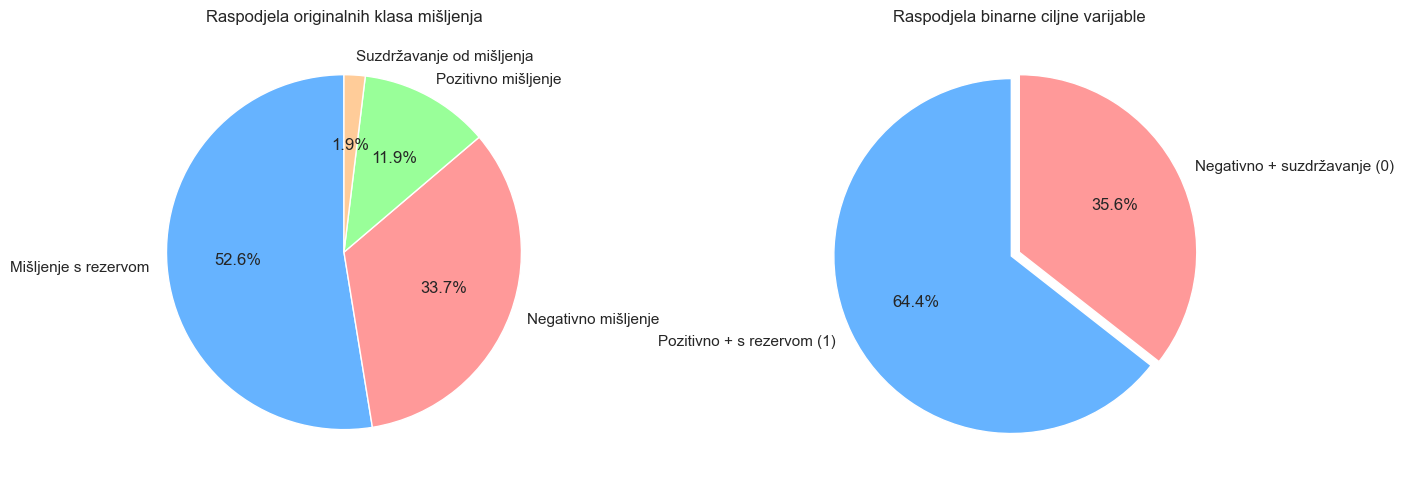

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df['misljenje'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90, ax=axes[0],
                                    colors=['#66b3ff', '#ff9999', '#99ff99', '#ffcc99'])
axes[0].set_title('Raspodjela originalnih klasa mišljenja')
axes[0].set_ylabel('')

df['cilj_binarno'].map({1: 'Pozitivno + s rezervom (1)', 0: 'Negativno + suzdržavanje (0)'}) \
    .value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90, explode=(0.05, 0), ax=axes[1],
                         colors=['#66b3ff', '#ff9999'])
axes[1].set_title('Raspodjela binarne ciljne varijable')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

Binarna raspodjela (oko 64% / 36%) dovoljno je uravnotežena za klasifikaciju. Originalne 4 klase nisu pogodne za modeliranje jer klasa *suzdržavanje* ima samo 6 primjera.

The binary split (~64/36) is balanced enough for classification. The original four classes are not suitable because 'disclaimer of opinion' has only 6 examples.

## Calculating skewness and kurtosis - asimetrija i zaobljenost

In [11]:
skew_kurt = pd.DataFrame({
    'skewness': [skew(df[v].dropna()) for v in numericke],
    'kurtosis': [kurtosis(df[v].dropna(), fisher=True) for v in numericke]
}, index=numericke).round(3)
print(skew_kurt)

                        skewness  kurtosis
potrazivanja_kupci_t       4.480    30.907
prihod_prodaja_t           3.755    15.193
potrazivanja_kupci_t1      4.798    32.903
prihod_prodaja_t1          3.518    12.940
poslovni_rashodi_t1        3.774    15.752
poslovni_rashodi_t         3.989    17.883
obrtna_imovina_t           4.210    21.367
nekretnine_oprema_t        2.856     8.382
kratk_fin_plasmani_t       5.690    32.400
poslovna_imovina_t         2.367     5.249
obrtna_imovina_t1          4.217    21.200
nekretnine_oprema_t1       2.748     7.242
kratk_fin_plasmani_t1      6.030    37.099
poslovna_imovina_t1        2.349     5.164
amortizacija_t1            3.521    13.161
amortizacija_t             3.216     9.988
admin_rashodi_t            7.688    71.109
admin_rashodi_t1           7.328    65.338
kratk_obaveze_t            3.674    15.987
dugor_obaveze_t            8.525    85.455
kratk_obaveze_t1           3.742    16.361
dugor_obaveze_t1           7.529    65.258
novcani_tok

Sve finansijske pozicije imaju izrazito desnu asimetriju (veliki broj malih i nekoliko vrlo velikih preduzeća), pa se za modele osjetljive na skalu (LR, SVM, k-NN, MLP) primjenjuje signed log transformacija unutar pipeline-a.

All financial items are strongly right-skewed, so a signed-log transform is applied inside the pipeline for scale-sensitive models.

## Filling missing values - popunjavanje nedostajućih vrijednosti
Ako je |skewness| > 1 koristi se medijan, inače mean. (U modelima se popunjavanje radi unutar pipeline-a – `SimpleImputer(median)` – da ne bi došlo do curenja podataka.)

In [12]:
for var in numericke:
    if df[var].isnull().any():
        sk = skew(df[var].dropna())
        metoda = 'median' if abs(sk) > 1 else 'mean'
        val = df[var].median() if metoda == 'median' else df[var].mean()
        df[var] = df[var].fillna(val)
        print(f"{var}: skew={sk:.3f} -> popunjeno sa {metoda} = {val:,.0f}")
print("\nPreostale missing vrijednosti u numeričkim varijablama:", int(df[numericke].isnull().sum().sum()))

nekretnine_oprema_t: skew=2.856 -> popunjeno sa median = 16,680,198
nekretnine_oprema_t1: skew=2.748 -> popunjeno sa median = 16,249,854
amortizacija_t1: skew=3.521 -> popunjeno sa median = 1,236,009
amortizacija_t: skew=3.216 -> popunjeno sa median = 1,331,563
novcani_tok_poslovni_t: skew=-1.742 -> popunjeno sa median = 597,032

Preostale missing vrijednosti u numeričkim varijablama: 0


## Descriptive statistic - deskriptivna statistika

In [13]:
pd.options.display.float_format = '{:,.2f}'.format
df[numericke].describe().T

,count,mean,std,min,25%,50%,75%,max
potrazivanja_kupci_t,312.00,"15,921,516.25","34,062,419.47",0.00,"742,518.75","2,147,698.50","13,085,166.00","347,532,514.00"
prihod_prodaja_t,312.00,"89,275,579.44","196,669,869.07","195,826.00","4,704,766.75","16,655,526.50","69,443,463.50","1,274,763,145.00"
potrazivanja_kupci_t1,312.00,"16,526,547.48","37,694,288.07",0.00,"674,705.25","2,076,993.00","13,875,010.25","382,234,948.00"
prihod_prodaja_t1,312.00,"87,885,910.24","189,537,682.61","68,460.00","4,578,149.00","16,953,060.00","67,260,480.00","1,139,628,124.00"
poslovni_rashodi_t1,312.00,"82,879,751.20","175,596,160.54","427,014.00","4,910,293.50","19,869,675.00","66,718,241.75","1,217,523,074.00"
poslovni_rashodi_t,312.00,"84,890,682.57","183,077,229.08","445,178.00","4,998,940.50","19,720,154.00","66,233,766.75","1,306,910,856.00"
obrtna_imovina_t,312.00,"52,037,254.14","116,131,267.81","152,624.00","2,406,594.25","10,038,017.00","50,979,465.75","995,833,019.00"
nekretnine_oprema_t,312.00,"302,575,480.25","684,927,271.76","33,879.00","5,377,946.50","16,680,198.00","103,176,713.50","4,352,208,031.00"
kratk_fin_plasmani_t,312.00,"6,469,545.00","32,499,094.19",0.00,0.00,0.00,0.00,"240,666,387.00"
poslovna_imovina_t,312.00,"491,548,163.84","924,712,253.92","455,151.00","10,434,908.50","46,458,529.50","370,311,887.25","4,655,590,916.00"


In [14]:
# Deskriptivna statistika po klasama ciljne varijable (medijan, jer su podaci asimetrični)
df.groupby('cilj_binarno')[numericke].median().T.rename(columns={0: 'Negativno/suzdržavanje (0)', 1: 'Pozitivno/s rezervom (1)'})

cilj_binarno,Negativno/suzdržavanje (0),Pozitivno/s rezervom (1)
potrazivanja_kupci_t,"2,909,334.00","1,960,717.00"
prihod_prodaja_t,"13,099,028.00","22,680,756.00"
potrazivanja_kupci_t1,"2,674,040.00","1,881,653.00"
prihod_prodaja_t1,"12,667,595.00","22,680,756.00"
poslovni_rashodi_t1,"15,043,478.00","22,662,751.00"
poslovni_rashodi_t,"16,253,120.00","24,900,599.00"
obrtna_imovina_t,"9,634,049.00","11,212,186.00"
nekretnine_oprema_t,"20,518,263.00","13,997,229.00"
kratk_fin_plasmani_t,0.00,0.00
poslovna_imovina_t,"47,965,587.00","39,016,139.00"


## Histograms for numeric variables - histogrami (log skala)

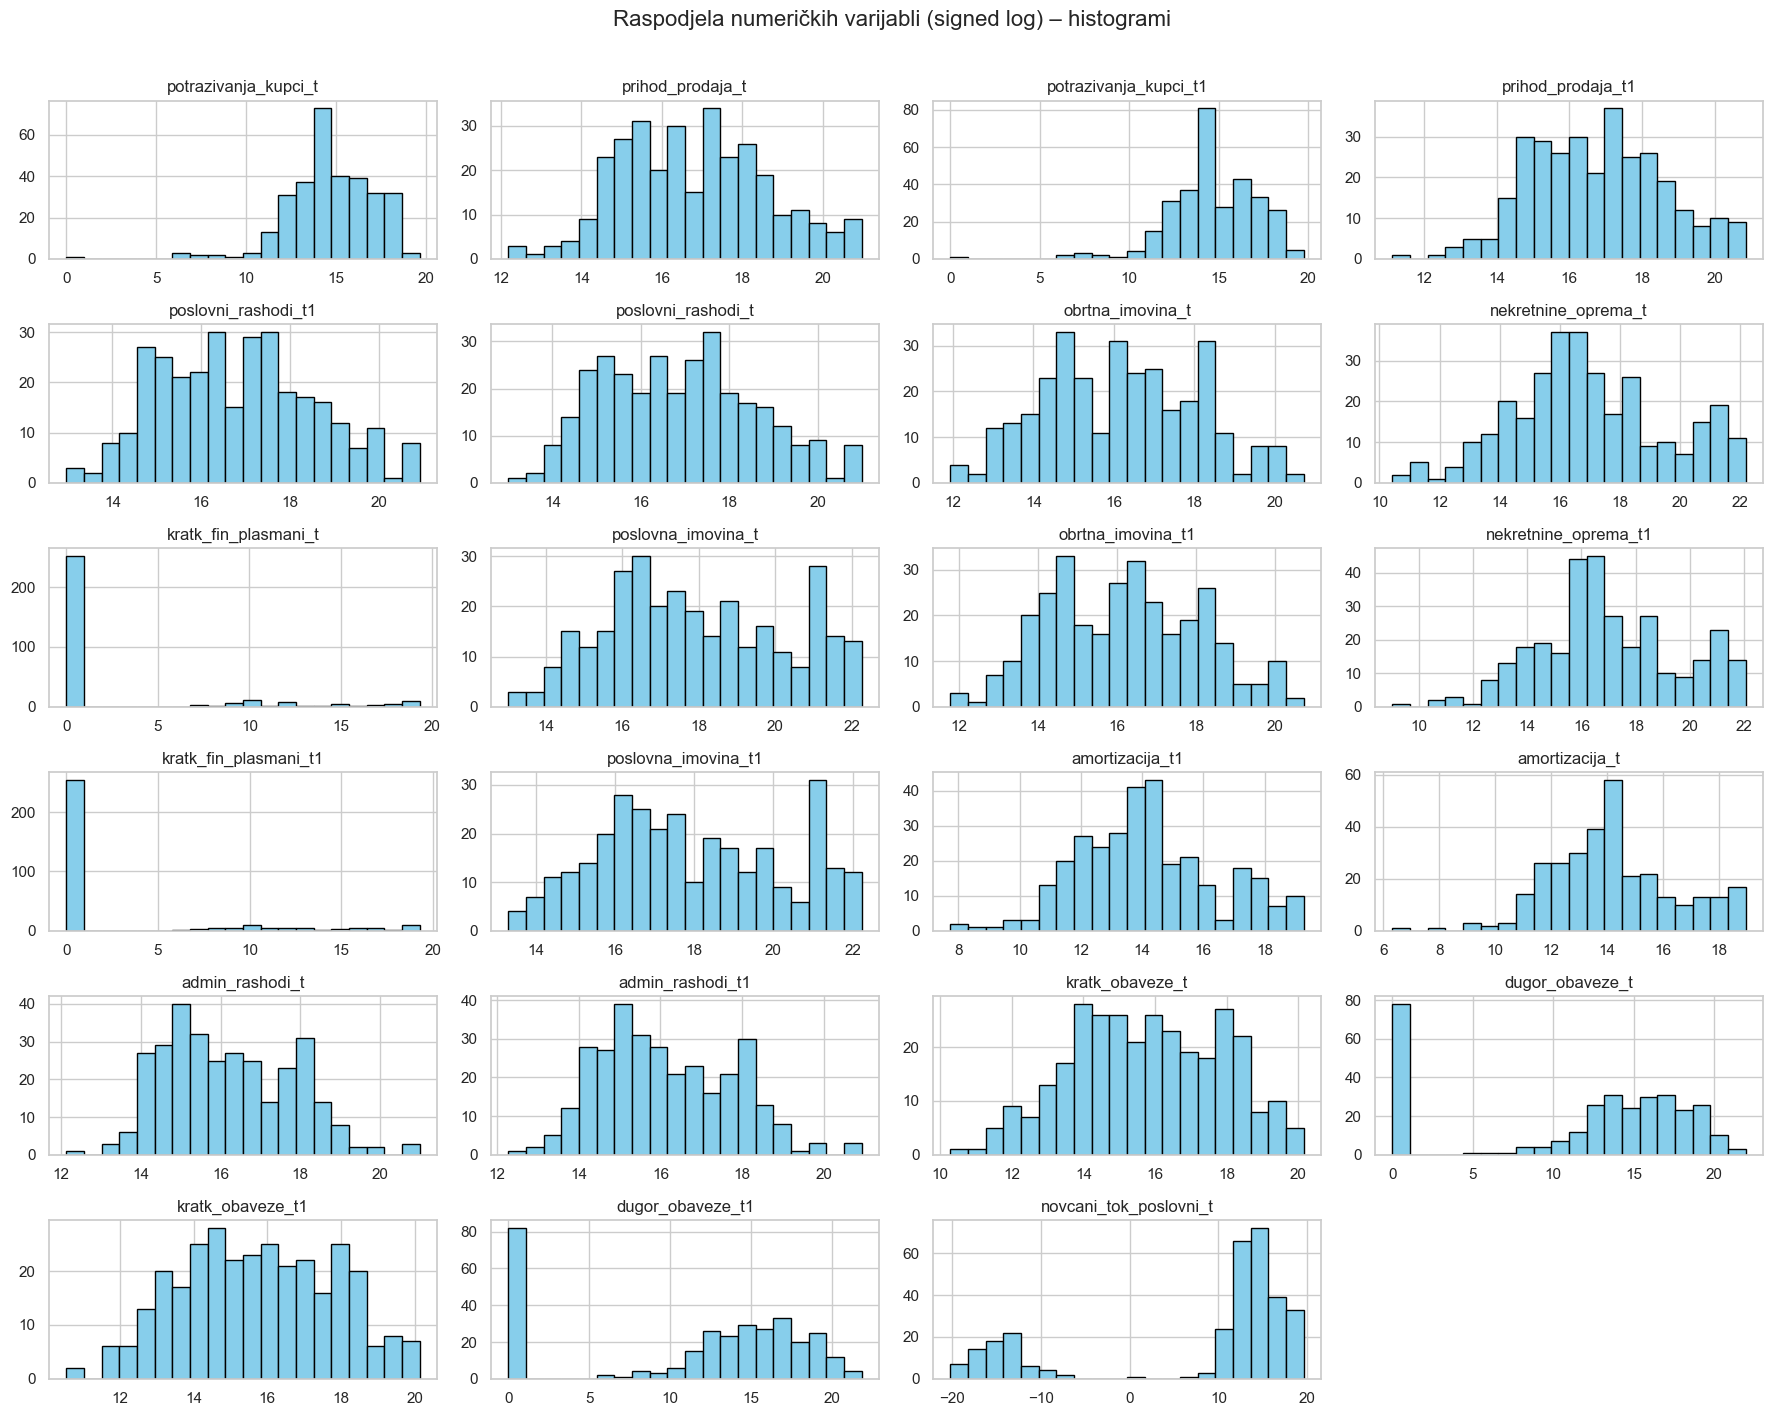

In [15]:
def slog(x):
    return np.sign(x) * np.log1p(np.abs(x))

df_log = df[numericke].apply(slog)

df_log.hist(bins=20, figsize=(18, 14), layout=(6, 4), color='skyblue', edgecolor='black')
plt.suptitle('Raspodjela numeričkih varijabli (signed log) – histogrami', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

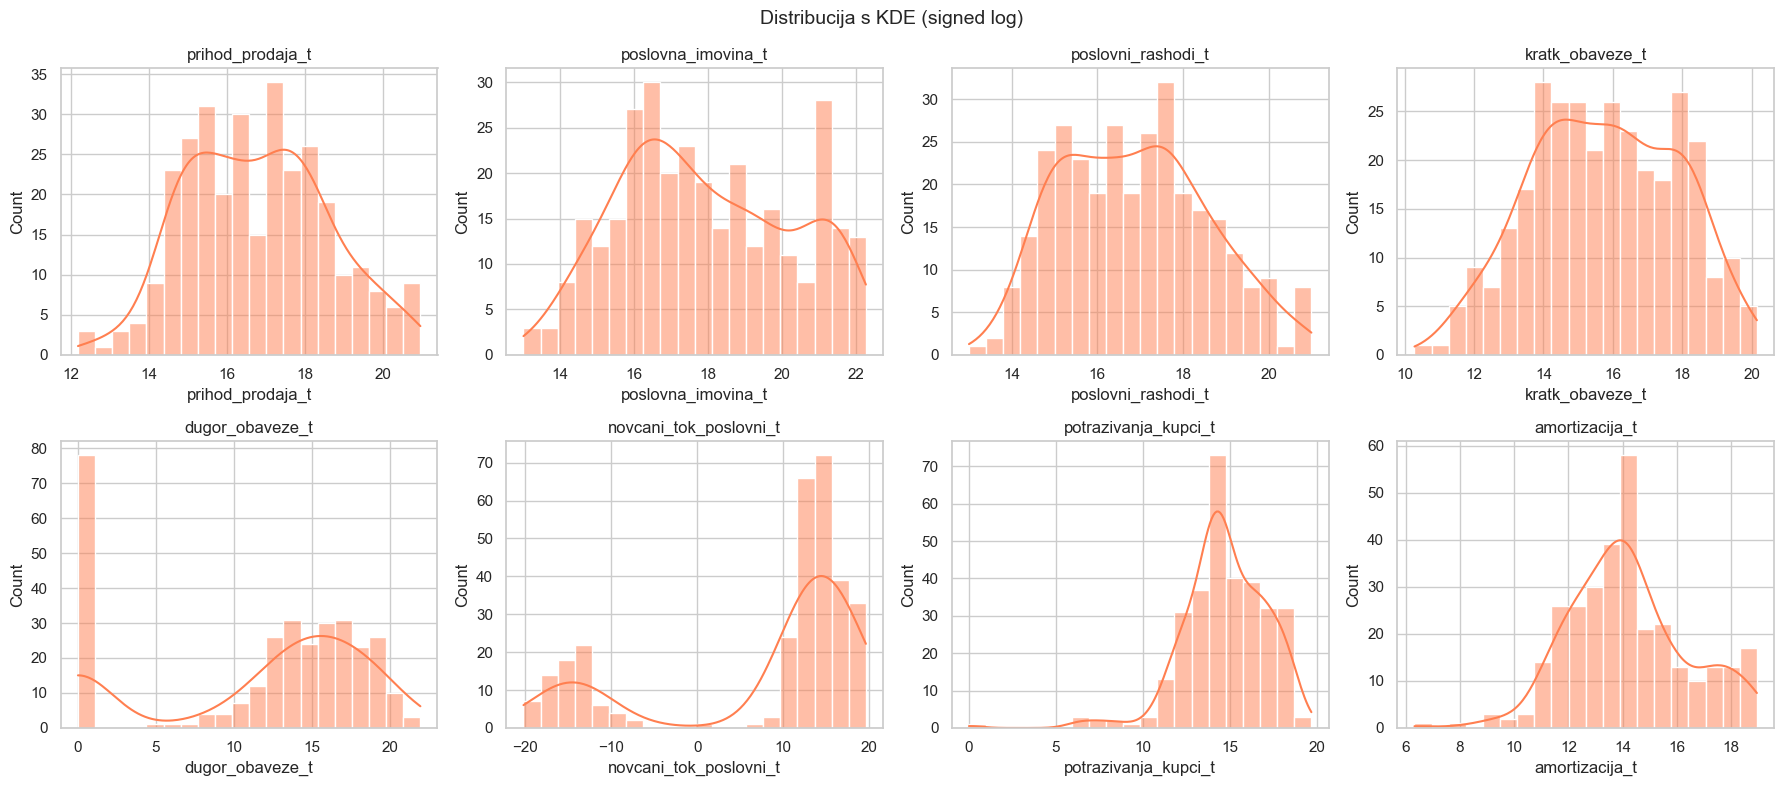

In [16]:
kljucne = ['prihod_prodaja_t', 'poslovna_imovina_t', 'poslovni_rashodi_t', 'kratk_obaveze_t',
           'dugor_obaveze_t', 'novcani_tok_poslovni_t', 'potrazivanja_kupci_t', 'amortizacija_t']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, var in enumerate(kljucne):
    sns.histplot(df_log[var], kde=True, bins=20, ax=axes[i], color='coral')
    axes[i].set_title(var)
plt.suptitle('Distribucija s KDE (signed log)', fontsize=14)
plt.tight_layout()
plt.show()

## Boxplots by opinion class - boxplot po klasi mišljenja

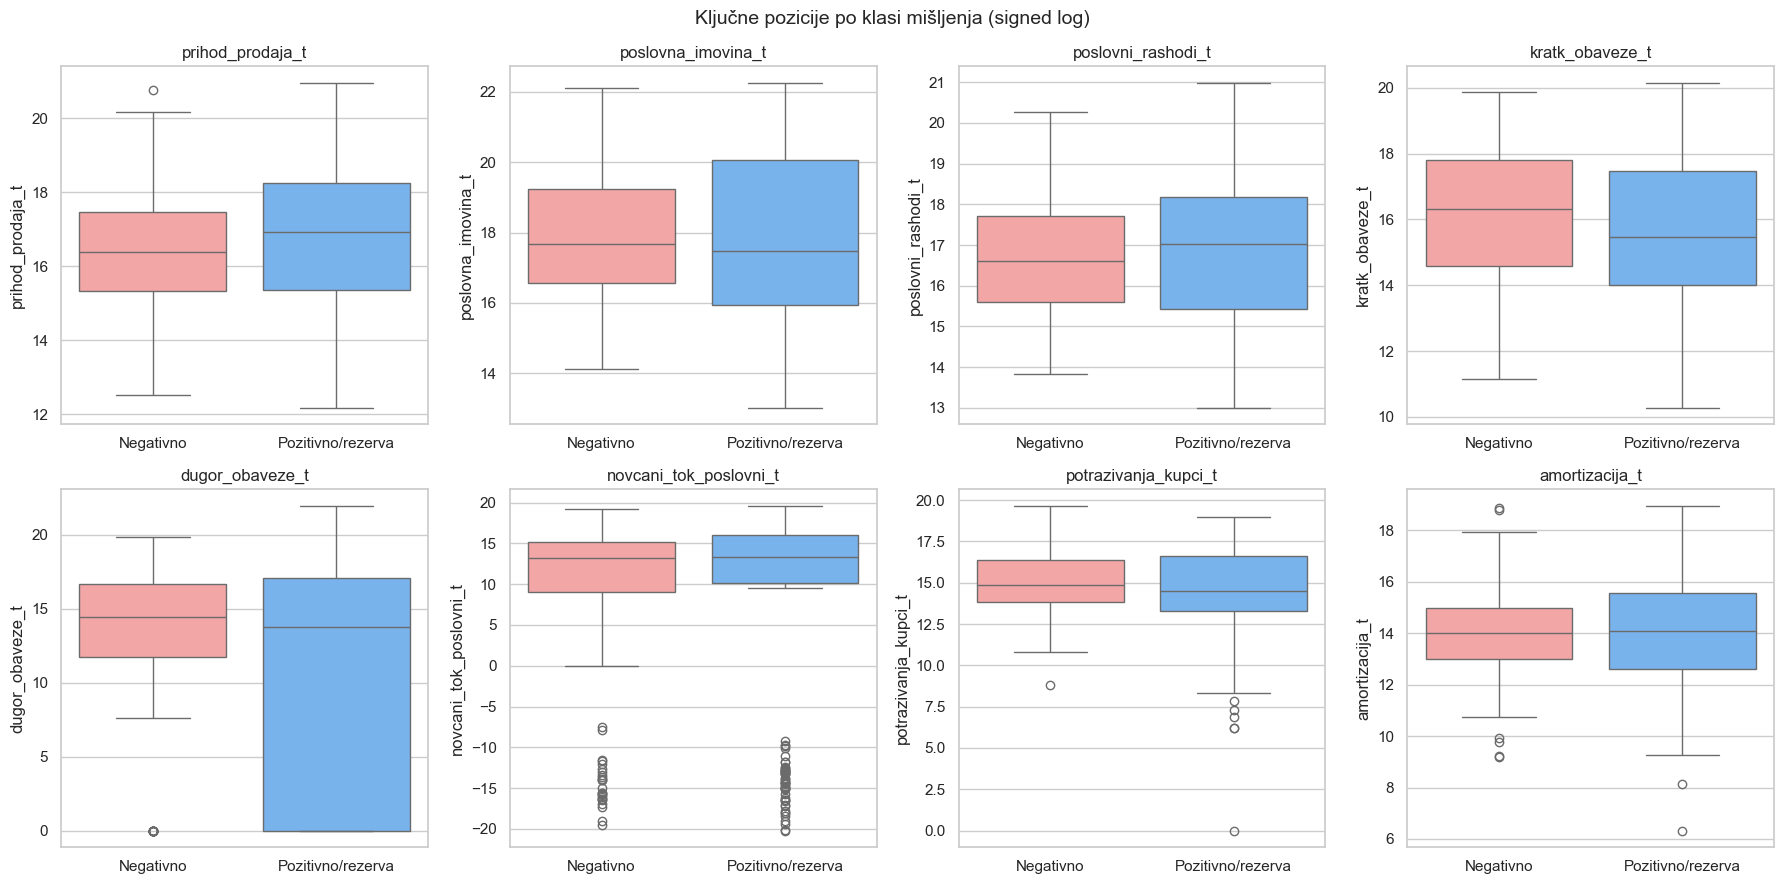

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()
for i, var in enumerate(kljucne):
    sns.boxplot(x=df['cilj_binarno'].map({0: 'Negativno', 1: 'Pozitivno/rezerva'}), y=df_log[var],
                ax=axes[i], palette=['#ff9999', '#66b3ff'])
    axes[i].set_title(var)
    axes[i].set_xlabel('')
plt.suptitle('Ključne pozicije po klasi mišljenja (signed log)', fontsize=14)
plt.tight_layout()
plt.show()

## Outliers - IQR analiza (bez uklanjanja)

In [18]:
q1 = df[numericke].quantile(0.25)
q3 = df[numericke].quantile(0.75)
iqr = q3 - q1
outlieri = ((df[numericke] < (q1 - 1.5 * iqr)) | (df[numericke] > (q3 + 1.5 * iqr))).sum().sort_values(ascending=False)
print(outlieri)

novcani_tok_poslovni_t    75
nekretnine_oprema_t       61
nekretnine_oprema_t1      61
poslovna_imovina_t        61
dugor_obaveze_t           60
dugor_obaveze_t1          60
poslovna_imovina_t1       60
kratk_fin_plasmani_t      60
kratk_fin_plasmani_t1     58
amortizacija_t1           54
amortizacija_t            53
potrazivanja_kupci_t      45
prihod_prodaja_t          42
poslovni_rashodi_t1       41
poslovni_rashodi_t        41
potrazivanja_kupci_t1     39
prihod_prodaja_t1         39
obrtna_imovina_t1         36
kratk_obaveze_t           34
kratk_obaveze_t1          33
obrtna_imovina_t          29
admin_rashodi_t           29
admin_rashodi_t1          28
dtype: int64


## Year and sector analysis - analiza po godinama i sektorima

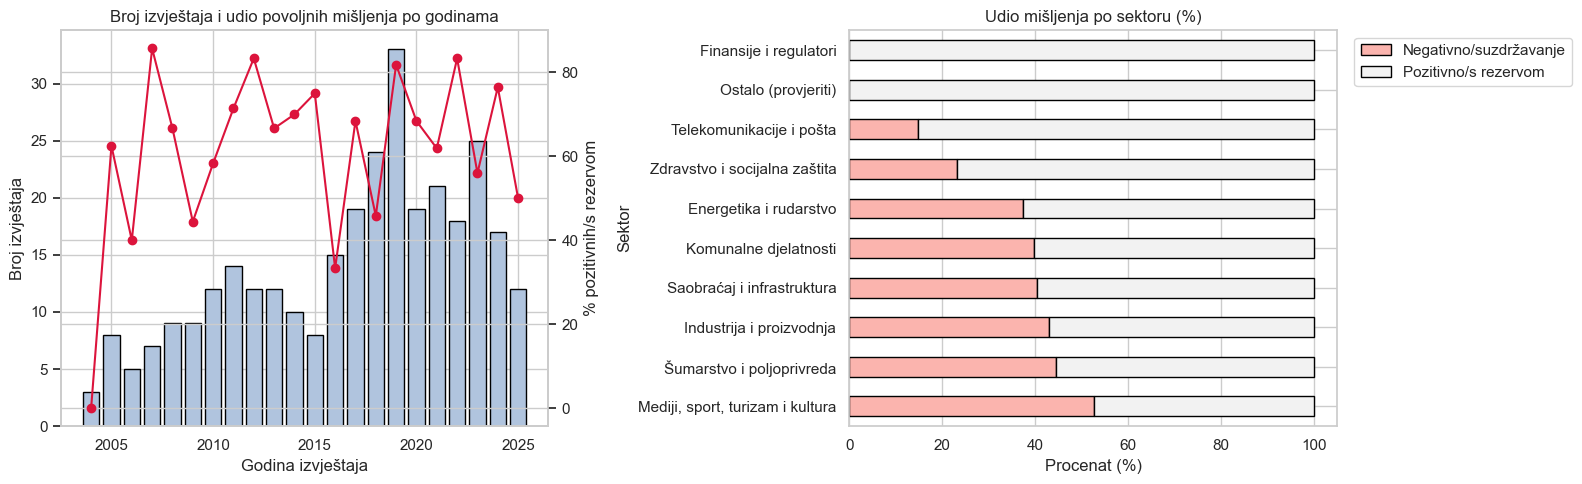

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

po_godini = df.dropna(subset=['Godina_izvjestaja']).groupby('Godina_izvjestaja')['cilj_binarno'].agg(['count', 'mean'])
axes[0].bar(po_godini.index, po_godini['count'], color='lightsteelblue', edgecolor='black')
axes[0].set_ylabel('Broj izvještaja')
axes[0].set_xlabel('Godina izvještaja')
ax2 = axes[0].twinx()
ax2.plot(po_godini.index, po_godini['mean'] * 100, color='crimson', marker='o')
ax2.set_ylabel('% pozitivnih/s rezervom')
axes[0].set_title('Broj izvještaja i udio povoljnih mišljenja po godinama')

crosstab = pd.crosstab(df['Sektor'], df['cilj_binarno'], normalize='index') * 100
crosstab.columns = ['Negativno/suzdržavanje', 'Pozitivno/s rezervom']
crosstab.sort_values('Pozitivno/s rezervom').plot(kind='barh', stacked=True, ax=axes[1], colormap='Pastel1', edgecolor='black')
axes[1].set_title('Udio mišljenja po sektoru (%)')
axes[1].set_xlabel('Procenat (%)')
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [21]:
print(df['Sektor'].value_counts())

Sektor
Komunalne djelatnosti               63
Saobraćaj i infrastruktura          62
Energetika i rudarstvo              59
Telekomunikacije i pošta            34
Šumarstvo i poljoprivreda           27
Zdravstvo i socijalna zaštita       26
Mediji, sport, turizam i kultura    19
Industrija i proizvodnja            14
Finansije i regulatori               7
Ostalo (provjeriti)                  1
Name: count, dtype: int64


In [22]:
contingency = pd.crosstab(df['Sektor'], df['cilj_binarno'], rownames=['Sektor'], colnames=['Povoljno mišljenje'])
print(contingency)
chi2, p_chi, dof, expected = chi2_contingency(contingency)
print(f"\nChi-square test: chi2 = {chi2:.4f}, dof = {dof}, p = {p_chi:.4f}")
print("Postoji značajna povezanost sektora i mišljenja (p<0.05)" if p_chi < 0.05 else "Nema značajne povezanosti")
print("Napomena: neka očekivana brojnost < 5 (mali sektori), rezultat tumačiti oprezno:",
      int((expected < 5).sum()), "ćelija")

Povoljno mišljenje                 0   1
Sektor                                  
Energetika i rudarstvo            22  37
Finansije i regulatori             0   7
Industrija i proizvodnja           6   8
Komunalne djelatnosti             25  38
Mediji, sport, turizam i kultura  10   9
Ostalo (provjeriti)                0   1
Saobraćaj i infrastruktura        25  37
Telekomunikacije i pošta           5  29
Zdravstvo i socijalna zaštita      6  20
Šumarstvo i poljoprivreda         12  15

Chi-square test: chi2 = 17.4614, dof = 9, p = 0.0420
Postoji značajna povezanost sektora i mišljenja (p<0.05)
Napomena: neka očekivana brojnost < 5 (mali sektori), rezultat tumačiti oprezno: 5 ćelija


Sektor je slabo, ali statistički značajno povezan s mišljenjem (telekomunikacije i pošta te zdravstvo imaju najveći udio povoljnih mišljenja). Sektor je dodjeljen automatski iz naziva preduzeća i treba ga ručno provjeriti.

Sector is weakly but significantly associated with the opinion. It was assigned automatically from the enterprise name and should be verified manually.

## Correlation matrix - korelacijska matrica

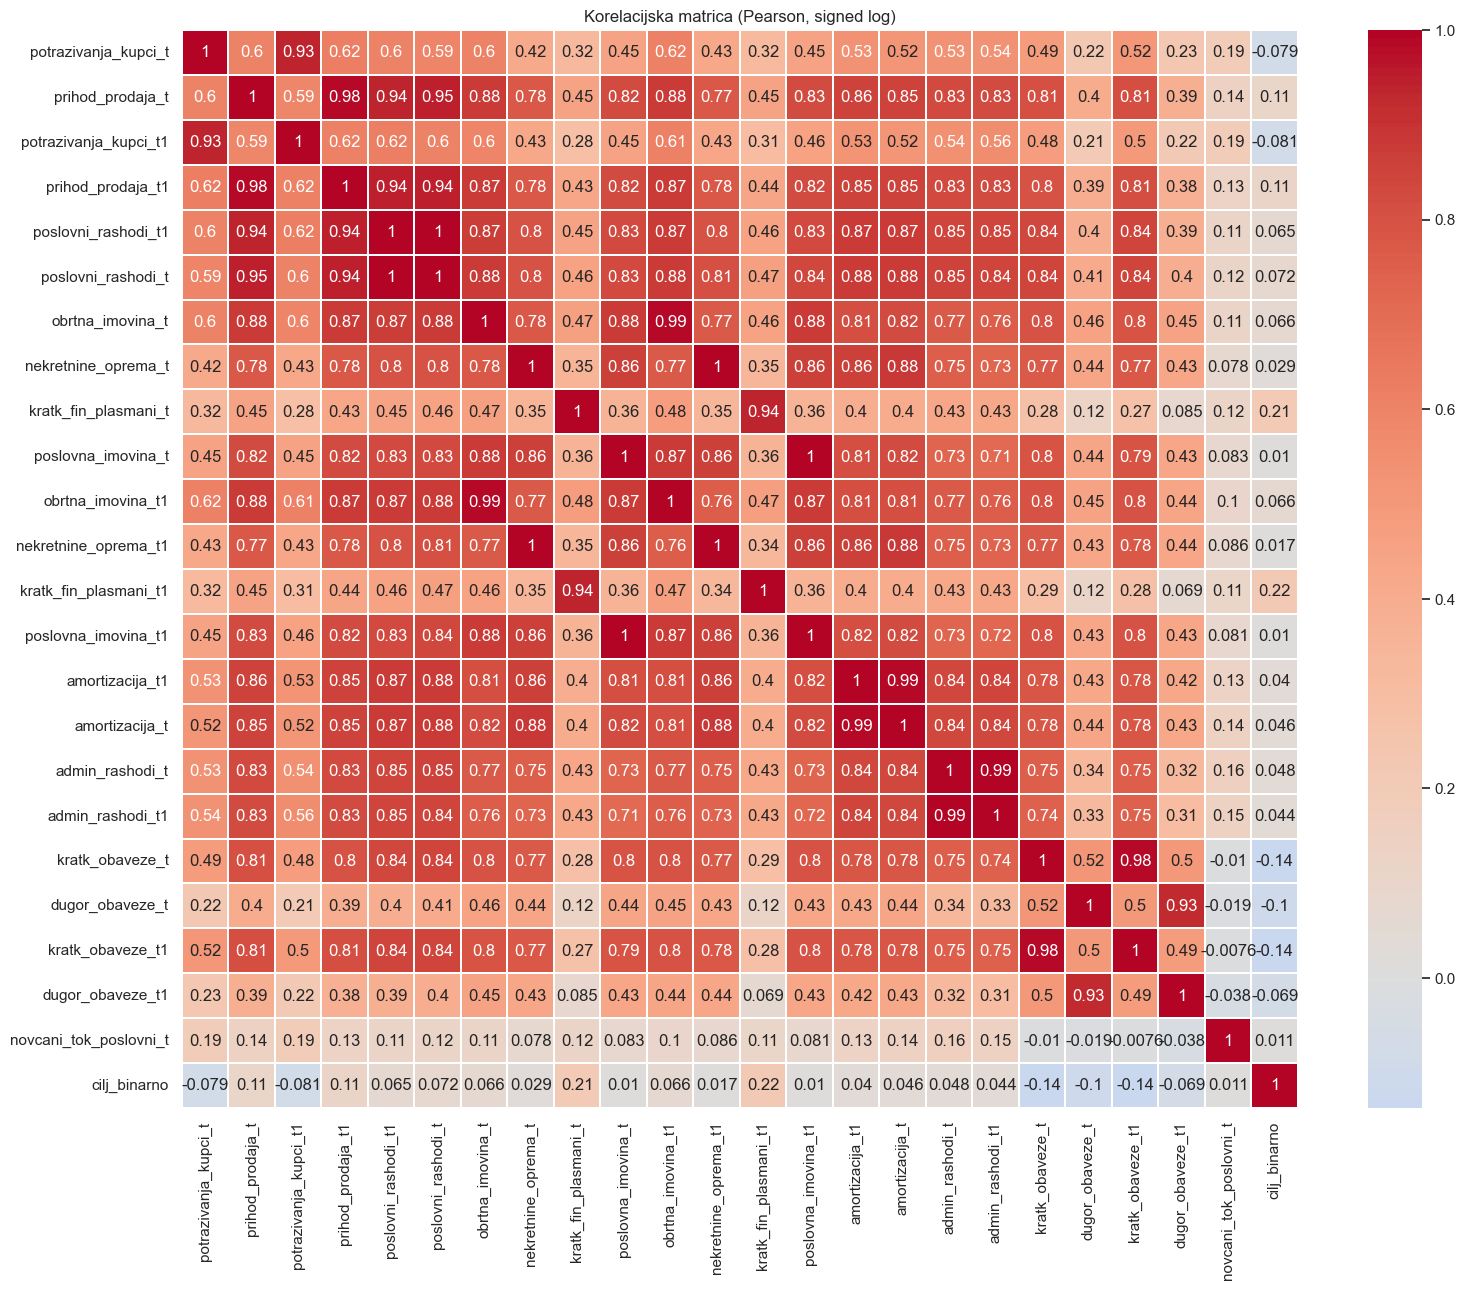

In [25]:
df_corr = df[numericke + ['cilj_binarno']].copy()
df_corr[numericke] = df_corr[numericke].apply(slog)   # signed log zbog asimetrije
correlation_matrix = df_corr.corr(method='pearson')

plt.figure(figsize=(18, 14))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, linewidths=0.3)
plt.title('Korelacijska matrica (Pearson, signed log)')
plt.show()

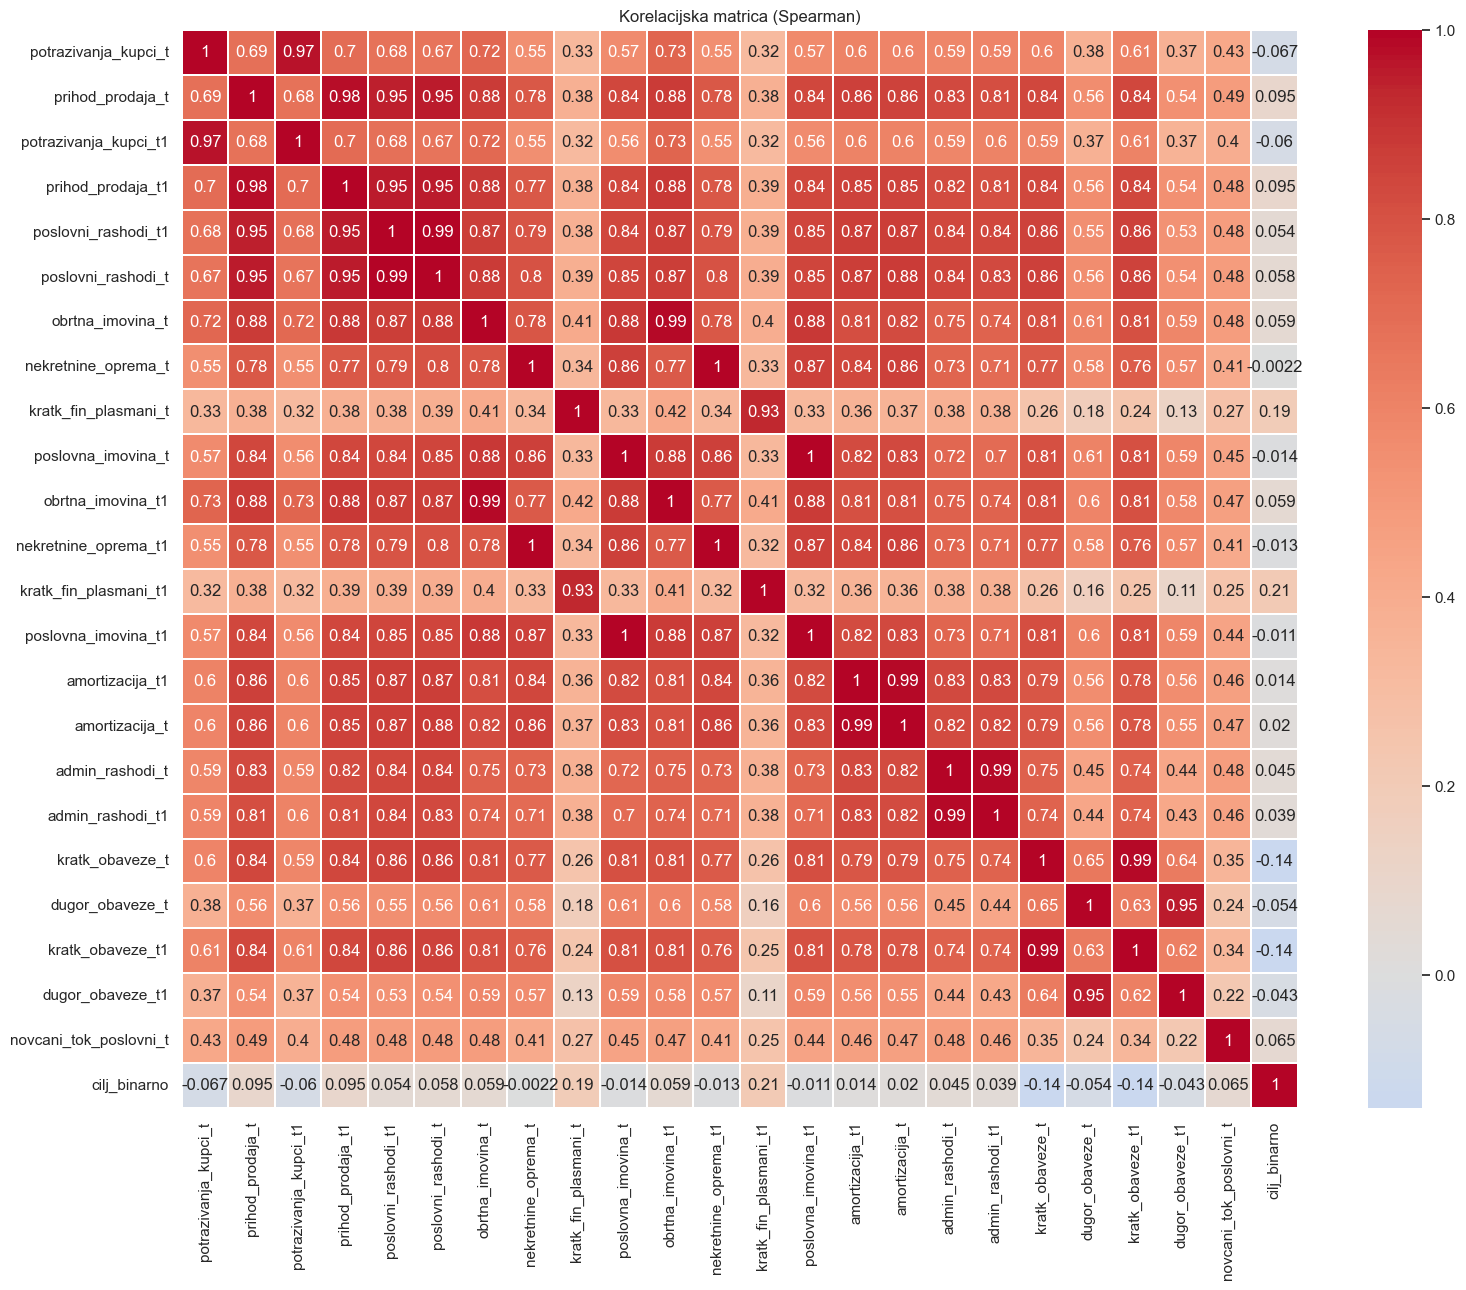

In [26]:
# Spearman (robustan na asimetriju i outliere)
spearman_matrix = df[numericke + ['cilj_binarno']].corr(method='spearman')
plt.figure(figsize=(18, 14))
sns.heatmap(spearman_matrix, annot=True, cmap='coolwarm', center=0, linewidths=0.3)
plt.title('Korelacijska matrica (Spearman)')
plt.show()

## Correlation with p-values - korelacije s p-vrijednostima

In [27]:
def korelacija_sa_p_vrijednostima(data, varijable=None):
    d = data[varijable].dropna() if varijable is not None else data.dropna()
    n = d.shape[1]
    corr = np.zeros((n, n)); pval = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            corr[i, j], pval[i, j] = pearsonr(d.iloc[:, i], d.iloc[:, j])
    return pd.DataFrame(corr, index=d.columns, columns=d.columns), pd.DataFrame(pval, index=d.columns, columns=d.columns)

korelacije, p_vrijednosti = korelacija_sa_p_vrijednostima(df_corr)

print("ZNAČAJNE KORELACIJE S CILJNOM VARIJABLOM (p < 0.05)")
print("=" * 70)
ciljne = pd.DataFrame({'r': korelacije['cilj_binarno'], 'p': p_vrijednosti['cilj_binarno']}).drop('cilj_binarno')
ciljne['znacajnost'] = ciljne['p'].apply(lambda p: '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else '')
print(ciljne.sort_values('r', key=abs, ascending=False).round(4))

ZNAČAJNE KORELACIJE S CILJNOM VARIJABLOM (p < 0.05)
                           r    p znacajnost
kratk_fin_plasmani_t1   0.22 0.00        ***
kratk_fin_plasmani_t    0.21 0.00        ***
kratk_obaveze_t1       -0.14 0.02          *
kratk_obaveze_t        -0.14 0.02          *
prihod_prodaja_t1       0.11 0.04          *
prihod_prodaja_t        0.11 0.06           
dugor_obaveze_t        -0.10 0.07           
potrazivanja_kupci_t1  -0.08 0.15           
potrazivanja_kupci_t   -0.08 0.16           
poslovni_rashodi_t      0.07 0.20           
dugor_obaveze_t1       -0.07 0.22           
obrtna_imovina_t1       0.07 0.25           
obrtna_imovina_t        0.07 0.25           
poslovni_rashodi_t1     0.07 0.25           
admin_rashodi_t         0.05 0.40           
amortizacija_t          0.05 0.42           
admin_rashodi_t1        0.04 0.43           
amortizacija_t1         0.04 0.48           
nekretnine_oprema_t     0.03 0.61           
nekretnine_oprema_t1    0.02 0.76           
nov

                           r    p
kratk_fin_plasmani_t1   0.22 0.00
kratk_fin_plasmani_t    0.21 0.00
kratk_obaveze_t1       -0.14 0.02
kratk_obaveze_t        -0.14 0.02
prihod_prodaja_t1       0.11 0.04
prihod_prodaja_t        0.11 0.06
dugor_obaveze_t        -0.10 0.07
potrazivanja_kupci_t1  -0.08 0.15
potrazivanja_kupci_t   -0.08 0.16
poslovni_rashodi_t      0.07 0.20
dugor_obaveze_t1       -0.07 0.22
obrtna_imovina_t1       0.07 0.25
obrtna_imovina_t        0.07 0.25
poslovni_rashodi_t1     0.07 0.25
admin_rashodi_t         0.05 0.40
amortizacija_t          0.05 0.42
admin_rashodi_t1        0.04 0.43
amortizacija_t1         0.04 0.48
nekretnine_oprema_t     0.03 0.61
nekretnine_oprema_t1    0.02 0.76
novcani_tok_poslovni_t  0.01 0.85
poslovna_imovina_t      0.01 0.86
poslovna_imovina_t1     0.01 0.86


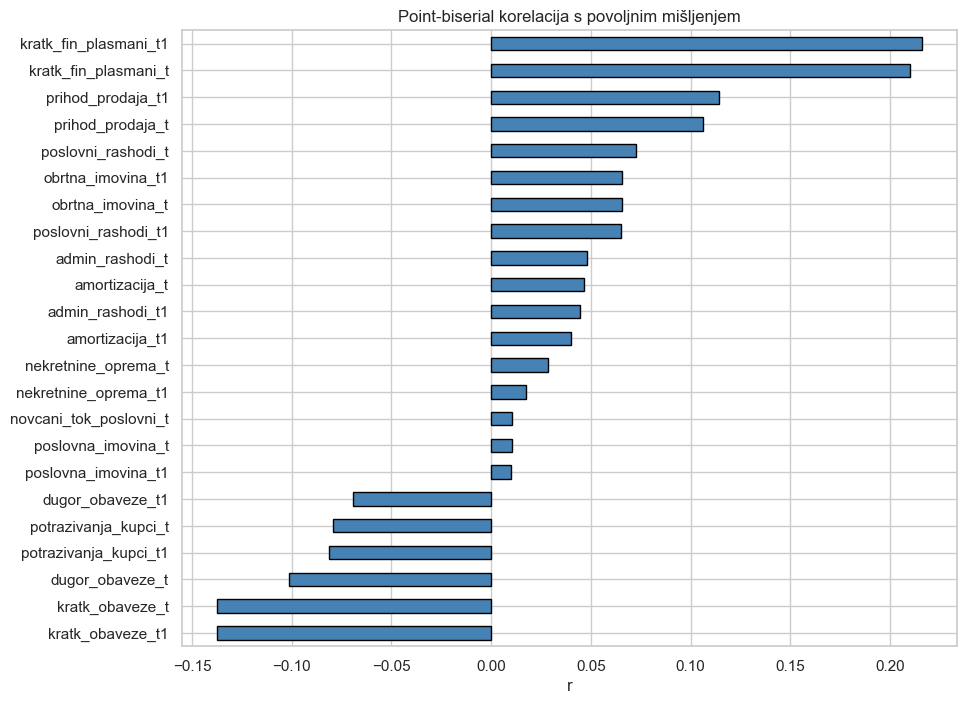

In [28]:
# Point-biserial korelacija (binarna cilj varijabla vs neprekidne varijable), na signed log vrijednostima
pb = {v: pointbiserialr(df['cilj_binarno'], slog(df[v])) for v in numericke}
pb_df = pd.DataFrame(pb, index=['r', 'p']).T.sort_values('r', key=abs, ascending=False)
print(pb_df.round(4))

pb_df['r'].sort_values().plot(kind='barh', figsize=(10, 8), color='steelblue', edgecolor='black')
plt.title('Point-biserial korelacija s povoljnim mišljenjem')
plt.xlabel('r')
plt.show()

In [29]:
# Parovi s visokom međusobnom korelacijom (multikolinearnost), |r| > 0.95
visoke = [(korelacije.index[i], korelacije.columns[j], korelacije.iloc[i, j])
          for i in range(len(numericke)) for j in range(i + 1, len(numericke))
          if abs(korelacije.iloc[i, j]) > 0.95 and korelacije.index[i] != 'cilj_binarno']
print("Broj parova s |r| > 0.95:", len(visoke))
for a, b, r in sorted(visoke, key=lambda t: -abs(t[2]))[:15]:
    print(f"{a:28s} {b:28s} r = {r:.3f}")

Broj parova s |r| > 0.95: 8
poslovna_imovina_t           poslovna_imovina_t1          r = 0.998
nekretnine_oprema_t          nekretnine_oprema_t1         r = 0.996
poslovni_rashodi_t1          poslovni_rashodi_t           r = 0.995
admin_rashodi_t              admin_rashodi_t1             r = 0.993
amortizacija_t1              amortizacija_t               r = 0.987
obrtna_imovina_t             obrtna_imovina_t1            r = 0.986
prihod_prodaja_t             prihod_prodaja_t1            r = 0.983
kratk_obaveze_t              kratk_obaveze_t1             r = 0.983


Pozicije tekuće (t) i prethodne (t-1) godine su međusobno vrlo visoko korelirane (veličina preduzeća), što je očekivano; za stabla to nije problem, za logističku regresiju se koristi regularizacija.

Current and prior-year items are highly intercorrelated (firm size). This is not a problem for trees; logistic regression uses regularisation.

## Train and test split - dijeljenje dataseta
A) Slučajna stratifikovana podjela 80/20 .
B) Vremenska podjela: trening do 2019, test 2020 i kasnije (realniji scenarij primjene).

In [32]:
x = df[numericke]
y = df['cilj_binarno']
groups = df['ID_preduzeca']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0, stratify=y)
print("A) Slučajna podjela:", x_train.shape, x_test.shape)
print(y_test.value_counts())

maska_trening = df['Godina_izvjestaja'] <= 2019
maska_test = df['Godina_izvjestaja'] >= 2020
x_train_t, y_train_t = x[maska_trening], y[maska_trening]
x_test_t, y_test_t = x[maska_test], y[maska_test]
print("\nB) Vremenska podjela: trening", x_train_t.shape, "| test", x_test_t.shape)
print("Udio klase 1 u treningu: %.2f, u testu: %.2f" % (y_train_t.mean(), y_test_t.mean()))
assert len(x_train_t) + len(x_test_t) == len(df), "Neki redovi nisu obuhvaćeni vremenskom podjelom"
print("Svi redovi su obuhvaćeni:", len(x_train_t) + len(x_test_t), "od", len(df))

A) Slučajna podjela: (249, 23) (63, 23)
cilj_binarno
1    41
0    22
Name: count, dtype: int64

B) Vremenska podjela: trening (200, 23) | test (112, 23)
Udio klase 1 u treningu: 0.64, u testu: 0.66
Svi redovi su obuhvaćeni: 312 od 312


## Data scaling - skaliranje
Skaliranje i log-transformacija su unutar `Pipeline` objekata, tako da se parametri uče samo na trening dijelu (bez curenja podataka). Stabla ne trebaju skaliranje, ali koriste isti imputer.

In [33]:
log_tr = FunctionTransformer(slog, feature_names_out='one-to-one')

def pipe(model, scale=False):
    koraci = [('imp', SimpleImputer(strategy='median'))]
    if scale:
        koraci += [('log', log_tr), ('sc', StandardScaler())]
    koraci += [('m', model)]
    return Pipeline(koraci)

def napravi_modele():
    m = {
        "Logistic Regression": pipe(LogisticRegression(max_iter=2000, class_weight='balanced', C=0.5), scale=True),
        "Decision Tree (J48-like)": pipe(DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, class_weight='balanced', random_state=RS)),
        "Random Forest": pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced', random_state=RS)),
        "Gradient Boosting": pipe(GradientBoostingClassifier(n_estimators=100, max_depth=2, learning_rate=0.05, random_state=RS)),
        "SVM (RBF)": pipe(SVC(probability=True, class_weight='balanced', random_state=RS), scale=True),
        "k-NN (k=7)": pipe(KNeighborsClassifier(n_neighbors=7), scale=True),
        "Naive Bayes (BayesNet-like)": pipe(GaussianNB(), scale=True),
        "MLP": pipe(MLPClassifier(hidden_layer_sizes=(16,), alpha=0.01, max_iter=2000, random_state=RS), scale=True),
    }
    if HAS_XGB:
        m["XGBoost"] = pipe(XGBClassifier(n_estimators=100, max_depth=2, learning_rate=0.05, eval_metric='logloss', random_state=RS))
    return m
print(list(napravi_modele().keys()))

['Logistic Regression', 'Decision Tree (J48-like)', 'Random Forest', 'Gradient Boosting', 'SVM (RBF)', 'k-NN (k=7)', 'Naive Bayes (BayesNet-like)', 'MLP', 'XGBoost']


### Za k-NN, SVM, MLP i LR koristimo log + skaliranje jer ovise o udaljenostima/gradijentu. Stabla i boosting nisu osjetljivi na skalu.

### Function for evaluating classification model - funkcija za evaluaciju

In [34]:
def evaluate_classifier(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None
    metrics = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_proba) if y_proba is not None else None
    }
    return metrics, y_pred, y_proba

## A) Model comparison on random split - poređenje modela (slučajna podjela)

In [35]:
modeli = napravi_modele()
results = {}
for name, clf in modeli.items():
    metrics, _, _ = evaluate_classifier(clf, x_train, y_train, x_test, y_test)
    results[name] = metrics

compare_df = pd.DataFrame(results).T.round(4)
print("--- Poređenje algoritama (test set, slučajna podjela) ---")
print(compare_df.sort_values('F1 Score', ascending=False))
print("\nNajbolji algoritam po F1:", compare_df['F1 Score'].idxmax())
print("Baseline (uvijek klasa 1): accuracy =", round(y_test.mean(), 4))

  File "c:\Users\userr\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\userr\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\userr\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                

--- Poređenje algoritama (test set, slučajna podjela) ---
                             Accuracy  Precision  Recall  F1 Score  MCC  \
k-NN (k=7)                       0.78       0.79    0.90      0.84 0.49   
Random Forest                    0.78       0.85    0.80      0.82 0.52   
SVM (RBF)                        0.79       0.94    0.73      0.82 0.61   
XGBoost                          0.75       0.78    0.85      0.81 0.42   
Gradient Boosting                0.75       0.79    0.83      0.81 0.43   
MLP                              0.76       0.86    0.76      0.81 0.51   
Decision Tree (J48-like)         0.70       0.79    0.73      0.76 0.36   
Logistic Regression              0.68       0.84    0.63      0.72 0.39   
Naive Bayes (BayesNet-like)      0.63       0.91    0.49      0.63 0.40   

                             ROC AUC  
k-NN (k=7)                      0.82  
Random Forest                   0.84  
SVM (RBF)                       0.85  
XGBoost                         0.7

### Confusion matrix - matrica konfuzije

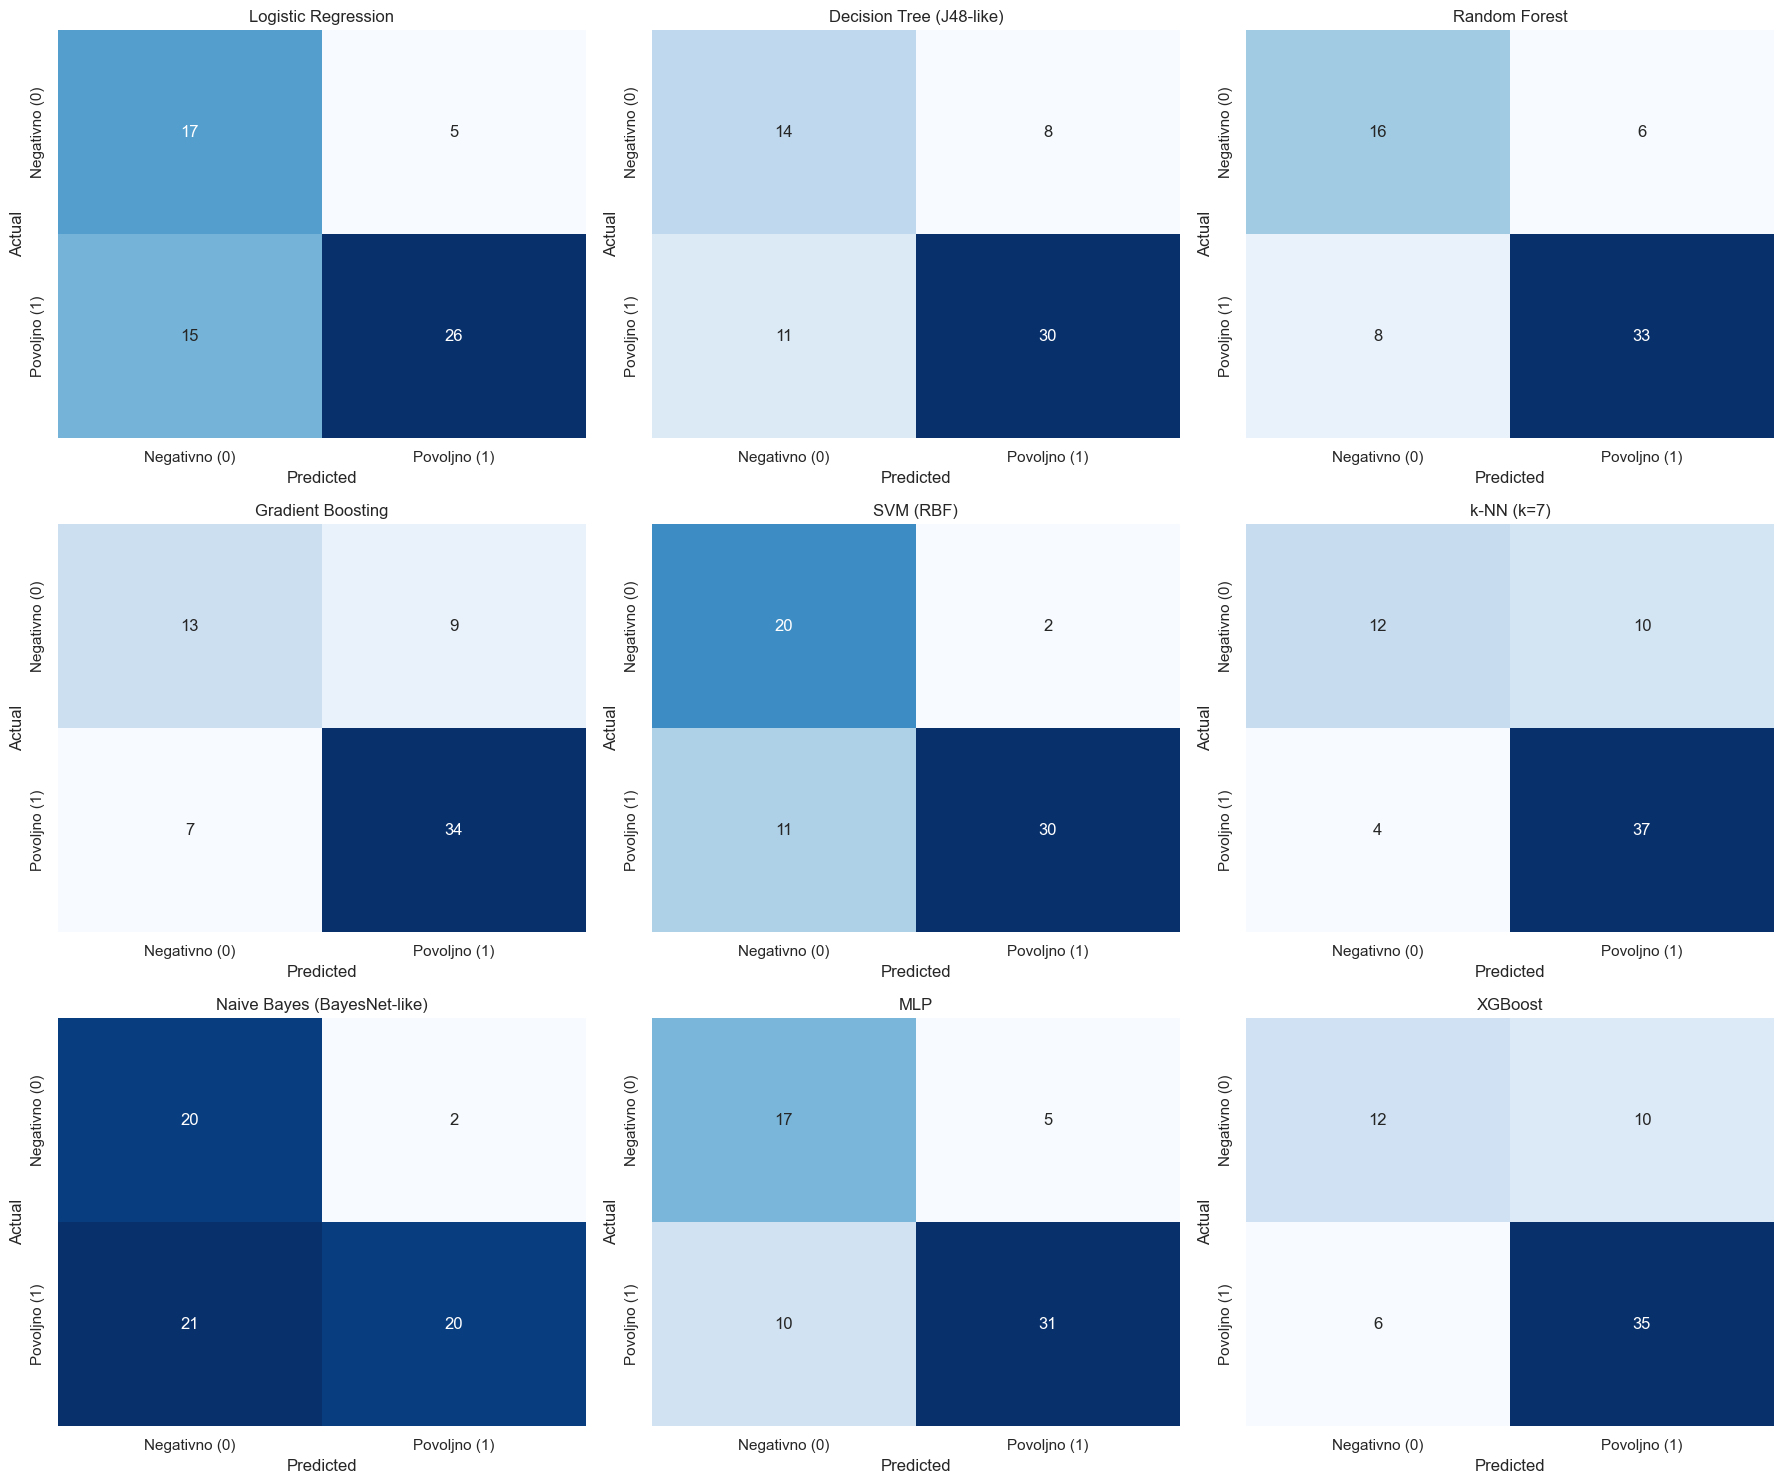


--- Numeričke vrijednosti konfuzijskih matrica ---
Logistic Regression            TN= 17 FP=  5 FN= 15 TP= 26
Decision Tree (J48-like)       TN= 14 FP=  8 FN= 11 TP= 30
Random Forest                  TN= 16 FP=  6 FN=  8 TP= 33
Gradient Boosting              TN= 13 FP=  9 FN=  7 TP= 34
SVM (RBF)                      TN= 20 FP=  2 FN= 11 TP= 30
k-NN (k=7)                     TN= 12 FP= 10 FN=  4 TP= 37
Naive Bayes (BayesNet-like)    TN= 20 FP=  2 FN= 21 TP= 20
MLP                            TN= 17 FP=  5 FN= 10 TP= 31
XGBoost                        TN= 12 FP= 10 FN=  6 TP= 35


In [36]:
nazivi_klasa = ['Negativno (0)', 'Povoljno (1)']
n_mod = len(modeli)
kolone = 3
redovi = int(np.ceil(n_mod / kolone))
fig, axes = plt.subplots(redovi, kolone, figsize=(18, 5 * redovi))
axes = axes.flatten()

for idx, (name, model) in enumerate(modeli.items()):
    model.fit(x_train, y_train)
    cm = confusion_matrix(y_test, model.predict(x_test))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False,
                xticklabels=nazivi_klasa, yticklabels=nazivi_klasa)
    axes[idx].set_title(name)
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')
for j in range(n_mod, len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

print("\n--- Numeričke vrijednosti konfuzijskih matrica ---")
for name, model in modeli.items():
    tn, fp, fn, tp = confusion_matrix(y_test, model.predict(x_test)).ravel()
    print(f"{name:30s} TN={tn:3d} FP={fp:3d} FN={fn:3d} TP={tp:3d}")

U ovoj aplikaciji lažno negativni (FN) su slučajevi u kojima model procijeni povoljno mišljenje, a revizor izda negativno; to je skuplja greška od lažno pozitivnog. Zato su uz accuracy važni recall za klasu 0 i ROC-AUC.

A costly error here is predicting a favourable opinion when the auditor issues an unfavourable one; therefore recall for class 0 and ROC-AUC matter alongside accuracy.

## ROC curves - ROC krive

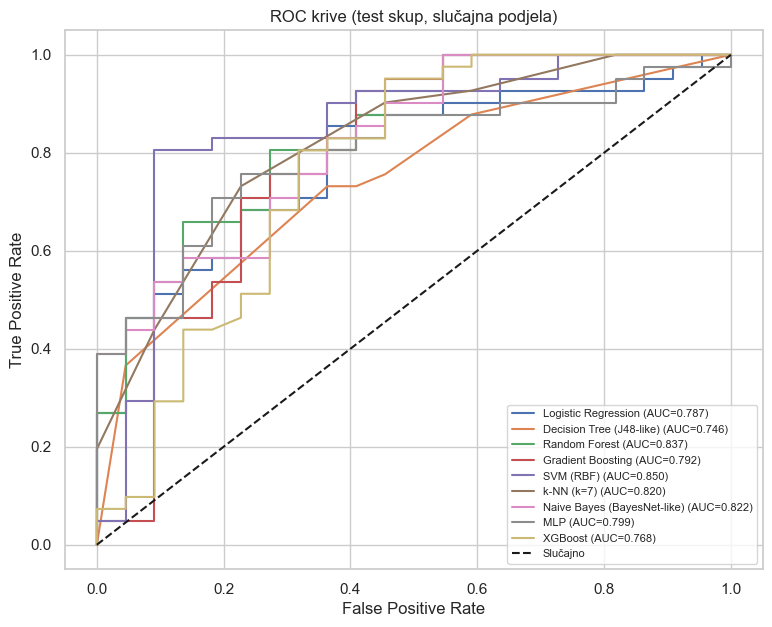

In [37]:
plt.figure(figsize=(9, 7))
for name, model in modeli.items():
    model.fit(x_train, y_train)
    proba = model.predict_proba(x_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Slučajno')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC krive (test skup, slučajna podjela)')
plt.legend(fontsize=8, loc='lower right')
plt.show()

## B) Temporal test (train <= 2019, test >= 2020) - vremenski test

In [38]:
modeli_t = napravi_modele()
res_t = {}
for name, clf in modeli_t.items():
    metrics, _, _ = evaluate_classifier(clf, x_train_t, y_train_t, x_test_t, y_test_t)
    res_t[name] = metrics
temporal_df = pd.DataFrame(res_t).T.round(4)
print(temporal_df.sort_values('ROC AUC', ascending=False))
print("\nBaseline (uvijek klasa 1): accuracy =", round(y_test_t.mean(), 4))

                             Accuracy  Precision  Recall  F1 Score  MCC  \
MLP                              0.71       0.76    0.84      0.79 0.33   
SVM (RBF)                        0.60       0.80    0.53      0.63 0.25   
k-NN (k=7)                       0.70       0.76    0.80      0.78 0.31   
Random Forest                    0.69       0.77    0.76      0.76 0.31   
Logistic Regression              0.56       0.82    0.43      0.57 0.25   
Gradient Boosting                0.65       0.73    0.76      0.74 0.21   
XGBoost                          0.62       0.71    0.73      0.72 0.15   
Naive Bayes (BayesNet-like)      0.47       0.78    0.28      0.42 0.14   
Decision Tree (J48-like)         0.62       0.72    0.72      0.72 0.16   

                             ROC AUC  
MLP                             0.76  
SVM (RBF)                       0.75  
k-NN (k=7)                      0.71  
Random Forest                   0.69  
Logistic Regression             0.69  
Gradient Boosti

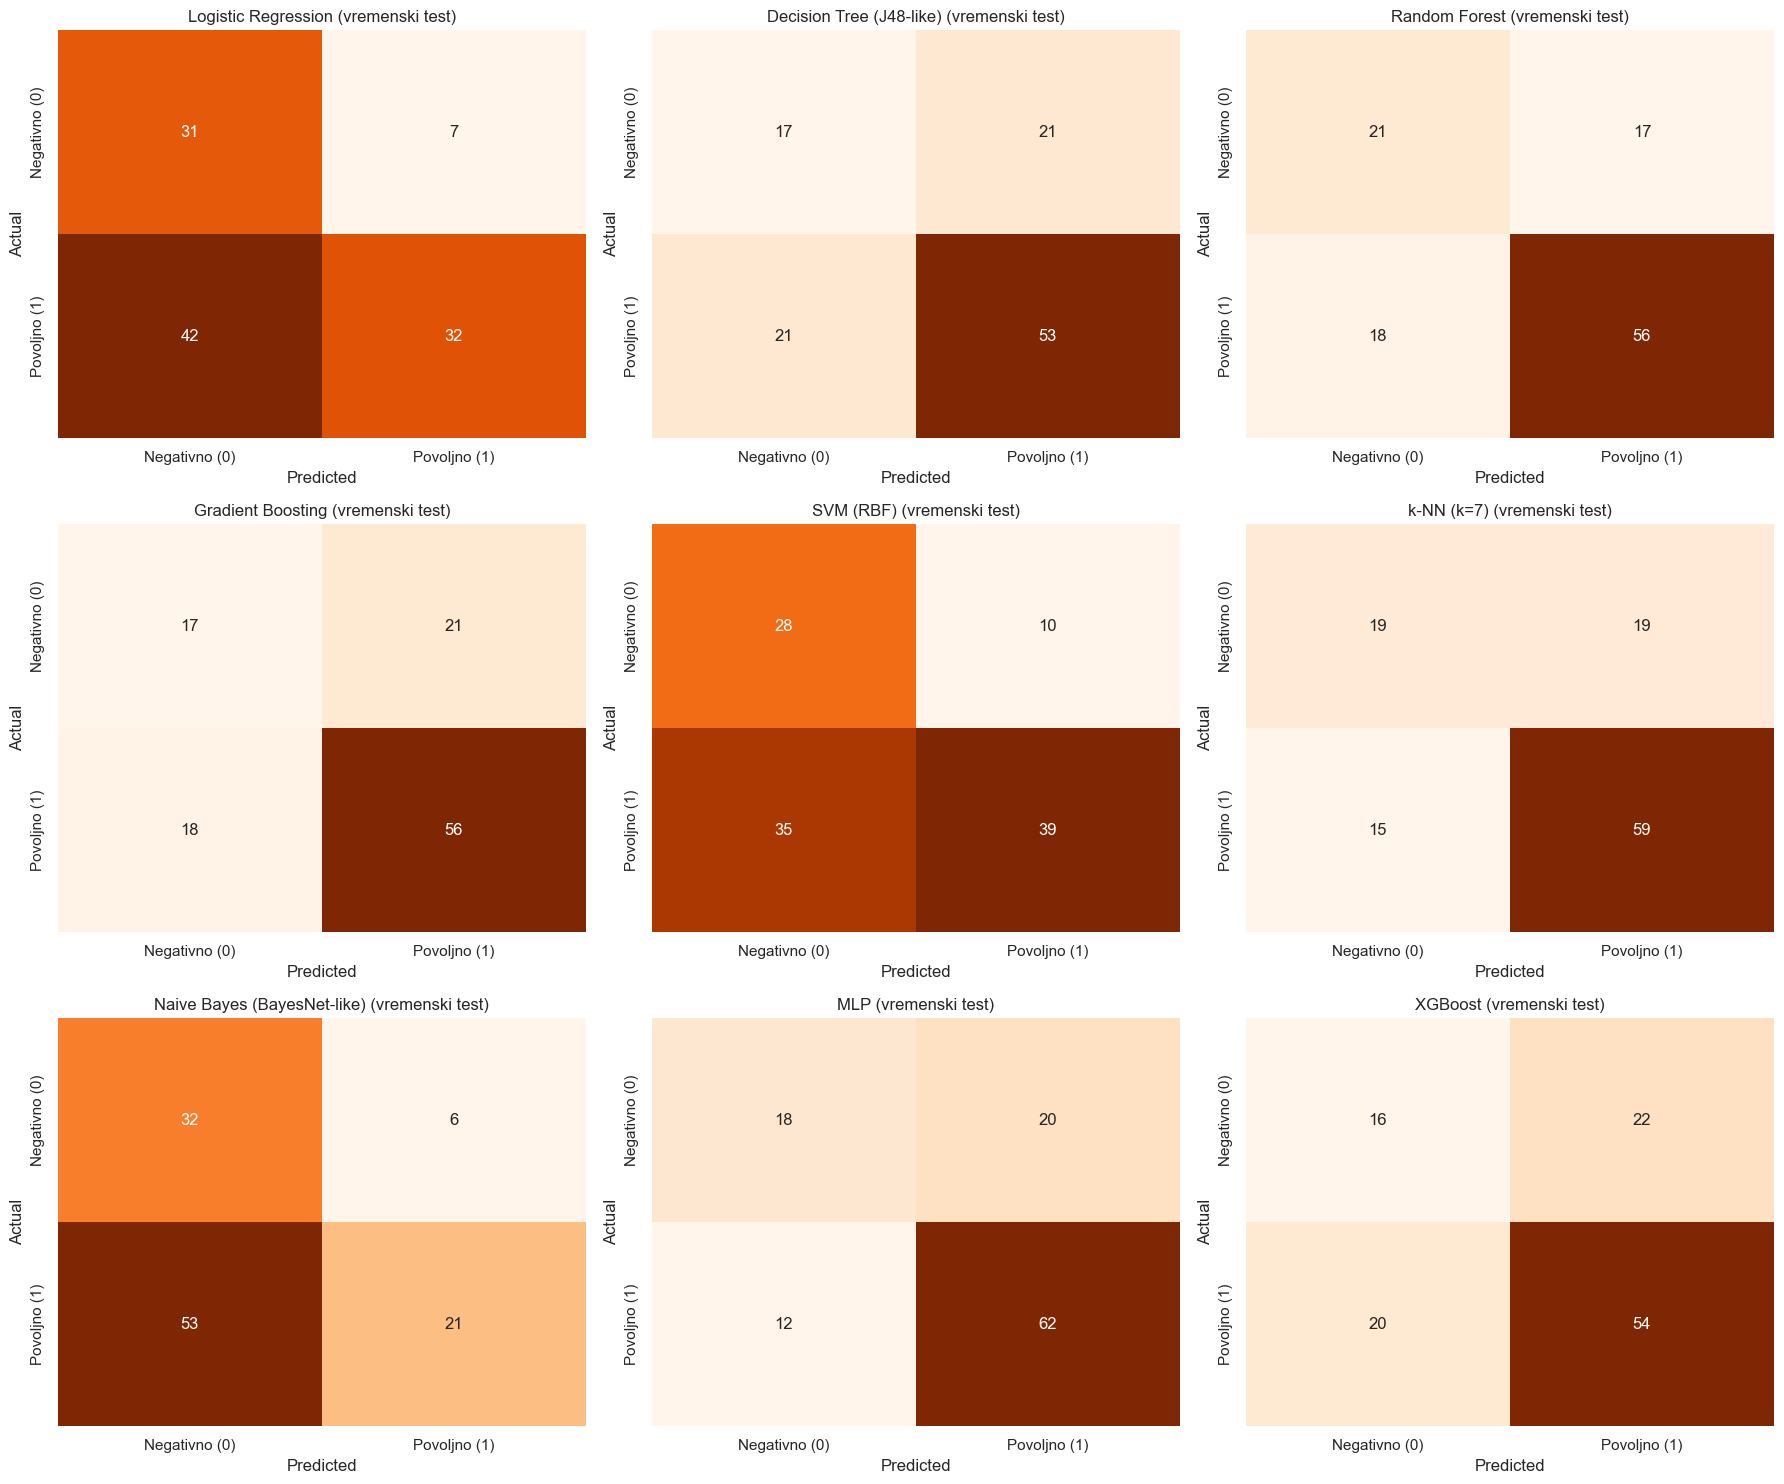

In [39]:
fig, axes = plt.subplots(redovi, kolone, figsize=(18, 5 * redovi))
axes = axes.flatten()
for idx, (name, model) in enumerate(modeli_t.items()):
    model.fit(x_train_t, y_train_t)
    cm = confusion_matrix(y_test_t, model.predict(x_test_t))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=axes[idx], cbar=False,
                xticklabels=nazivi_klasa, yticklabels=nazivi_klasa)
    axes[idx].set_title(name + ' (vremenski test)')
    axes[idx].set_xlabel('Predicted'); axes[idx].set_ylabel('Actual')
for j in range(n_mod, len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

## 10-fold cross-validation (stratified) - 10-struka križna validacija
Obavezno prema uputama; ponovljena 3 puta radi stabilnijih procjena.

In [40]:
scoring = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall',
           'f1': 'f1', 'roc_auc': 'roc_auc'}

def cv_tabela(cv_factory, groups_arg=None, ponavljanja=3):
    redovi_tab = []
    for name, model in napravi_modele().items():
        sve = {m: [] for m in scoring}
        for r in range(ponavljanja):
            cv = cv_factory(r)
            if groups_arg is None:
                s = cross_validate(model, x, y, cv=cv, scoring=scoring, n_jobs=-1)
            else:
                s = cross_validate(model, x, y, cv=cv, groups=groups_arg, scoring=scoring, n_jobs=-1)
            for m in scoring:
                sve[m].append(np.mean(s[f'test_{m}']))
        redovi_tab.append({'Model': name,
                           **{f'mean_{m}': np.mean(v) for m, v in sve.items()},
                           **{f'std_{m}': np.std(v) for m, v in sve.items()}})
    return pd.DataFrame(redovi_tab).round(4).sort_values('mean_roc_auc', ascending=False)

cv10 = cv_tabela(lambda r: StratifiedKFold(n_splits=10, shuffle=True, random_state=r))
print("=== 10-FOLD CV (stratifikovana) ===")
print(cv10[['Model', 'mean_accuracy', 'mean_precision', 'mean_recall', 'mean_f1', 'mean_roc_auc', 'std_roc_auc']])

=== 10-FOLD CV (stratifikovana) ===
                         Model  mean_accuracy  mean_precision  mean_recall  \
4                    SVM (RBF)           0.72            0.82         0.72   
7                          MLP           0.73            0.78         0.82   
0          Logistic Regression           0.68            0.80         0.68   
2                Random Forest           0.71            0.75         0.84   
8                      XGBoost           0.72            0.73         0.88   
3            Gradient Boosting           0.72            0.74         0.88   
5                   k-NN (k=7)           0.70            0.74         0.84   
6  Naive Bayes (BayesNet-like)           0.55            0.76         0.45   
1     Decision Tree (J48-like)           0.60            0.71         0.64   

   mean_f1  mean_roc_auc  std_roc_auc  
4     0.76          0.79         0.01  
7     0.80          0.77         0.01  
0     0.73          0.77         0.00  
2     0.79          0.7

## 5-fold cross-validation grouped by enterprise - validacija po preduzećima
Isto preduzeće se pojavljuje u više godina; ako se te godine nađu i u trening i u test dijelu, rezultat je optimističan. `StratifiedGroupKFold` drži sve godine jednog preduzeća u istom dijelu.

In [41]:
cvg = cv_tabela(lambda r: StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=r), groups_arg=groups)
print("=== 5-FOLD GROUP CV (po preduzećima) ===")
print(cvg[['Model', 'mean_accuracy', 'mean_precision', 'mean_recall', 'mean_f1', 'mean_roc_auc', 'std_roc_auc']])

=== 5-FOLD GROUP CV (po preduzećima) ===
                         Model  mean_accuracy  mean_precision  mean_recall  \
7                          MLP           0.70            0.76         0.78   
0          Logistic Regression           0.66            0.78         0.66   
4                    SVM (RBF)           0.68            0.79         0.70   
2                Random Forest           0.70            0.73         0.86   
5                   k-NN (k=7)           0.68            0.72         0.83   
8                      XGBoost           0.69            0.72         0.85   
6  Naive Bayes (BayesNet-like)           0.55            0.75         0.47   
3            Gradient Boosting           0.68            0.72         0.85   
1     Decision Tree (J48-like)           0.61            0.70         0.66   

   mean_f1  mean_roc_auc  std_roc_auc  
7     0.77          0.73         0.01  
0     0.71          0.73         0.01  
4     0.73          0.73         0.01  
2     0.79        

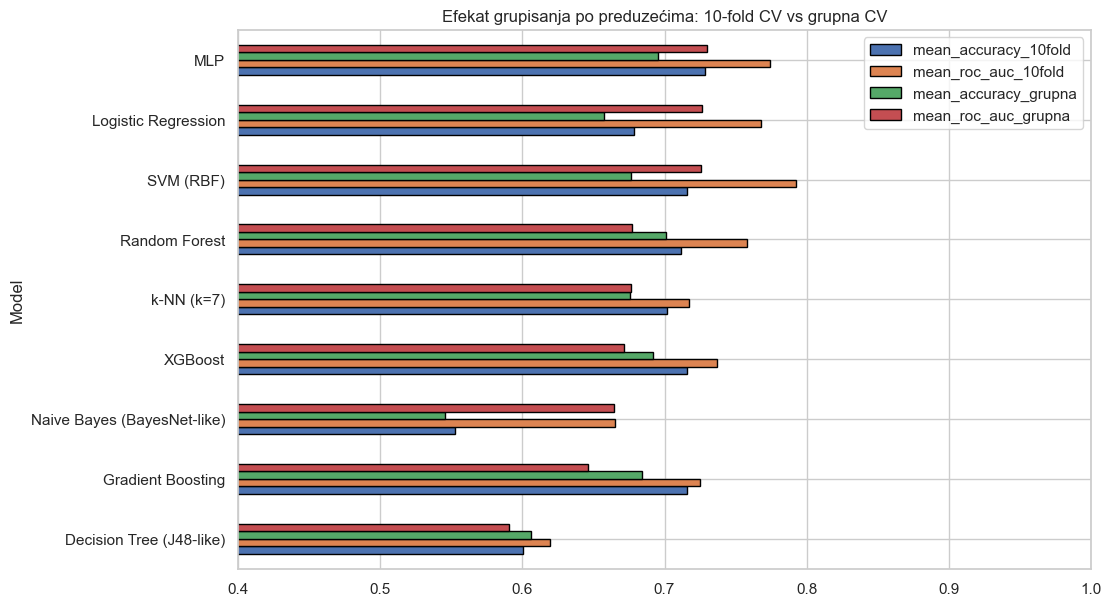

                             mean_accuracy_10fold  mean_roc_auc_10fold  \
Model                                                                    
SVM (RBF)                                    0.72                 0.79   
MLP                                          0.73                 0.77   
Logistic Regression                          0.68                 0.77   
Random Forest                                0.71                 0.76   
XGBoost                                      0.72                 0.74   
Gradient Boosting                            0.72                 0.72   
k-NN (k=7)                                   0.70                 0.72   
Naive Bayes (BayesNet-like)                  0.55                 0.67   
Decision Tree (J48-like)                     0.60                 0.62   

                             mean_accuracy_grupna  mean_roc_auc_grupna  
Model                                                                   
SVM (RBF)                              

In [42]:
poredjenje = cv10.set_index('Model')[['mean_accuracy', 'mean_roc_auc']].join(
    cvg.set_index('Model')[['mean_accuracy', 'mean_roc_auc']], lsuffix='_10fold', rsuffix='_grupna')
poredjenje.sort_values('mean_roc_auc_grupna').plot(kind='barh', figsize=(11, 7), edgecolor='black')
plt.title('Efekat grupisanja po preduzećima: 10-fold CV vs grupna CV')
plt.xlim(0.4, 1.0)
plt.show()
print(poredjenje.round(3))

Razlika između običnog i grupnog CV pokazuje koliko bi rezultat bio napuhan zbog ponavljanja istog preduzeća. Za izvještavanje se preporučuje grupna ili vremenska varijanta.

The gap between plain and grouped CV shows how much results would be inflated by repeated enterprises. Grouped or temporal results are recommended for reporting.

## Does sector help? - da li sektor poboljšava model
Poređenje skupa A (samo bilansne pozicije) i skupa B (bilansne pozicije + sektor, one-hot).

In [43]:
x_sek = pd.concat([x, pd.get_dummies(df['Sektor'], prefix='sek').astype(int)], axis=1)

def grupni_cv_skup(X_skup, model_fn, ponavljanja=5):
    out = []
    for r in range(ponavljanja):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=r)
        s = cross_validate(model_fn(), X_skup, y, cv=cv, groups=groups, scoring=['accuracy', 'roc_auc', 'f1'])
        out.append([np.mean(s['test_accuracy']), np.mean(s['test_roc_auc']), np.mean(s['test_f1'])])
    return np.mean(out, axis=0)

tab = []
for ime, fn in [("Random Forest", lambda: napravi_modele()["Random Forest"]),
                ("Logistic Regression", lambda: napravi_modele()["Logistic Regression"]),
                ("Gradient Boosting", lambda: napravi_modele()["Gradient Boosting"])]:
    a = grupni_cv_skup(x, fn); b = grupni_cv_skup(x_sek, fn)
    tab.append({'Model': ime, 'Acc (bez sektora)': a[0], 'Acc (sa sektorom)': b[0],
                'AUC (bez sektora)': a[1], 'AUC (sa sektorom)': b[1]})
sektor_df = pd.DataFrame(tab).round(3)
print(sektor_df)

                 Model  Acc (bez sektora)  Acc (sa sektorom)  \
0        Random Forest               0.71               0.71   
1  Logistic Regression               0.66               0.65   
2    Gradient Boosting               0.68               0.67   

   AUC (bez sektora)  AUC (sa sektorom)  
0               0.69               0.69  
1               0.73               0.70  
2               0.65               0.66  


## Feature importance - važnost značajki

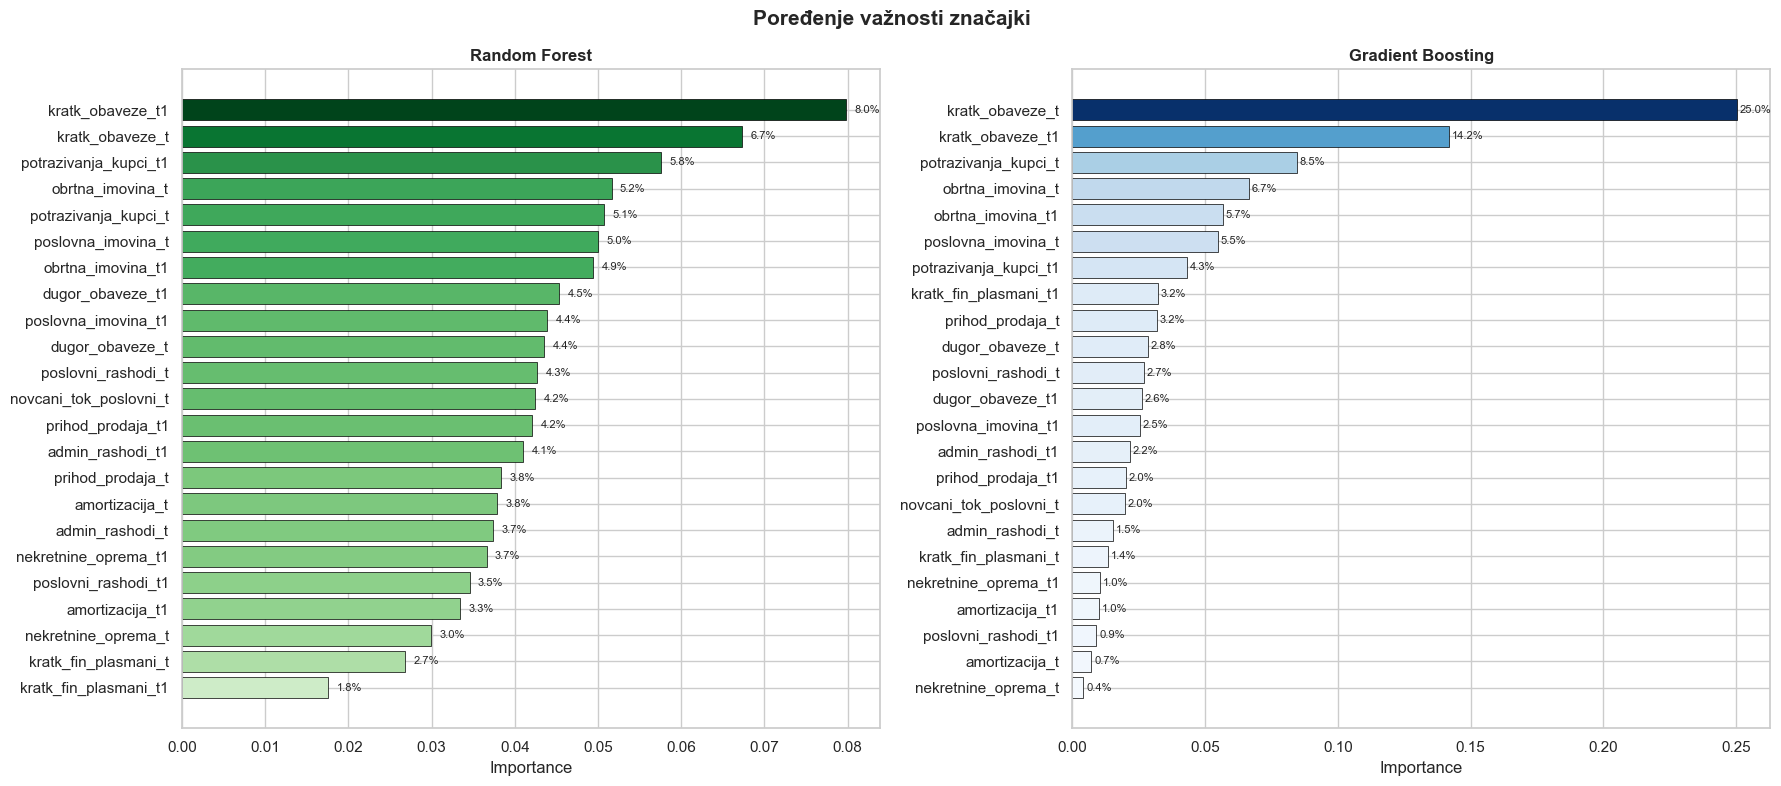

                  Feature  Importance  Importance_Pct
20       kratk_obaveze_t1        0.08            7.98
18        kratk_obaveze_t        0.07            6.73
2   potrazivanja_kupci_t1        0.06            5.75
6        obrtna_imovina_t        0.05            5.16
0    potrazivanja_kupci_t        0.05            5.07
9      poslovna_imovina_t        0.05            5.00
10      obrtna_imovina_t1        0.05            4.94
21       dugor_obaveze_t1        0.05            4.53


In [44]:
rf_model = pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced', random_state=RS))
rf_model.fit(x, y)
fi_rf = pd.DataFrame({'Feature': numericke, 'Importance': rf_model.named_steps['m'].feature_importances_}).sort_values('Importance', ascending=False)
fi_rf['Importance_Pct'] = fi_rf['Importance'] * 100

gb_model = pipe(GradientBoostingClassifier(n_estimators=100, max_depth=2, learning_rate=0.05, random_state=RS))
gb_model.fit(x, y)
fi_gb = pd.DataFrame({'Feature': numericke, 'Importance': gb_model.named_steps['m'].feature_importances_}).sort_values('Importance', ascending=False)
fi_gb['Importance_Pct'] = fi_gb['Importance'] * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))
for ax, fi, cmap, naslov in [(ax1, fi_rf, plt.cm.Greens, 'Random Forest'), (ax2, fi_gb, plt.cm.Blues, 'Gradient Boosting')]:
    boje = cmap(fi['Importance'] / fi['Importance'].max())
    bars = ax.barh(fi['Feature'], fi['Importance'], color=boje, edgecolor='black', linewidth=0.5)
    for b, imp, pct in zip(bars, fi['Importance'], fi['Importance_Pct']):
        ax.text(b.get_width() + 0.001, b.get_y() + b.get_height() / 2, f'{pct:.1f}%', va='center', fontsize=8)
    ax.invert_yaxis(); ax.set_title(naslov, fontweight='bold'); ax.set_xlabel('Importance')
plt.suptitle('Poređenje važnosti značajki', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()
print(fi_rf.head(8).round(4))

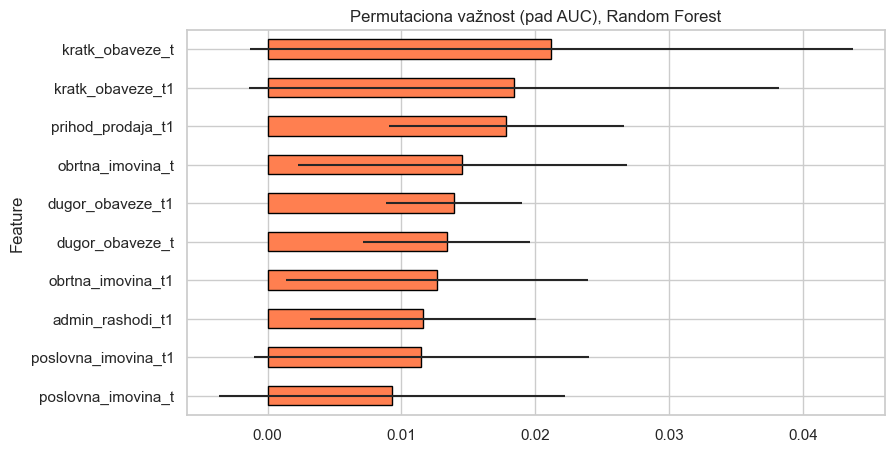

In [45]:
# Permutaciona važnost (pouzdanija od impurity importance) na test skupu
from sklearn.inspection import permutation_importance
rf_p = pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced', random_state=RS)).fit(x_train, y_train)
pi = permutation_importance(rf_p, x_test, y_test, scoring='roc_auc', n_repeats=30, random_state=RS)
pi_df = pd.DataFrame({'Feature': numericke, 'mean': pi.importances_mean, 'std': pi.importances_std}).sort_values('mean', ascending=False)
pi_df.head(10).iloc[::-1].plot(x='Feature', y='mean', xerr='std', kind='barh', legend=False, figsize=(9, 5), color='coral', edgecolor='black')
plt.title('Permutaciona važnost (pad AUC), Random Forest')
plt.show()

## Decision tree visualisation - vizualizacija stabla odlučivanja
Plitko stablo daje pravila čitljiva revizorima (analogno J48/REPTree iz rada).

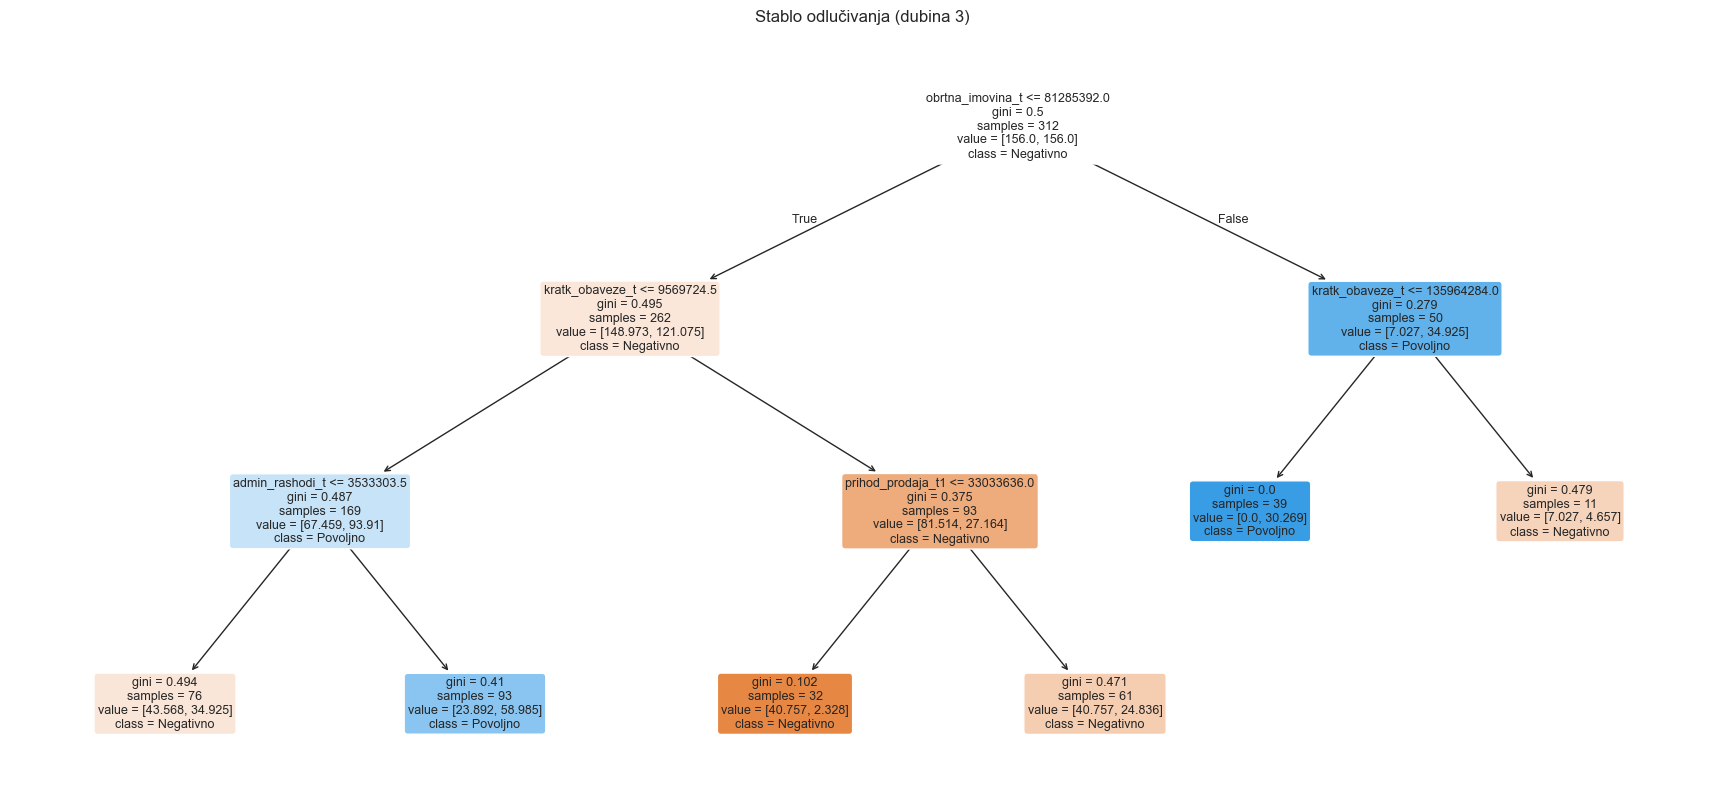

In [46]:
stablo = DecisionTreeClassifier(max_depth=3, min_samples_leaf=8, class_weight='balanced', random_state=RS)
stablo.fit(SimpleImputer(strategy='median').fit_transform(x), y)
plt.figure(figsize=(22, 10))
plot_tree(stablo, feature_names=numericke, class_names=['Negativno', 'Povoljno'], filled=True, rounded=True, fontsize=9)
plt.title('Stablo odlučivanja (dubina 3)')
plt.show()

## Risk ranking - rangiranje preduzeća po riziku (praktična primjena)
Revizori biraju samo 10-15 preduzeća godišnje. Mjerimo koliko se negativnih mišljenja nalazi među top-k preduzeća rangiranim po vjerovatnoći negativnog mišljenja (grupne out-of-fold predikcije).

Osnovni udio negativnih mišljenja: 0.356
   top-k  udio negativnih u top-k  lift
0     10                     0.70  1.97
1     15                     0.73  2.06
2     20                     0.75  2.11
3     30                     0.77  2.15
4     50                     0.70  1.97
5    100                     0.55  1.55


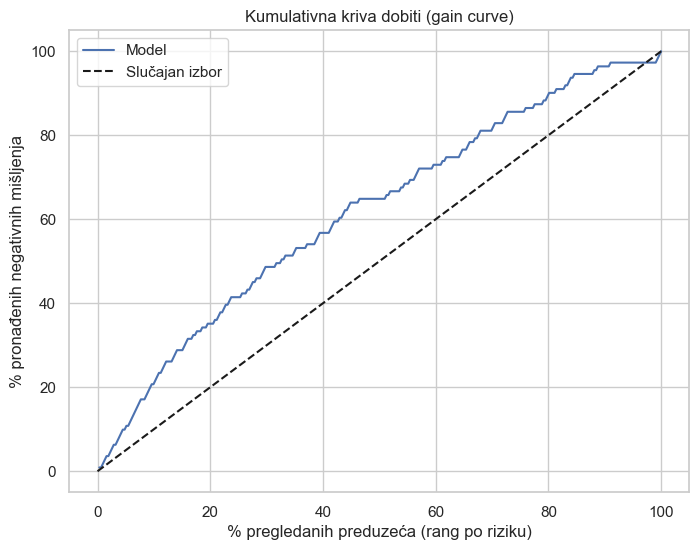

In [47]:
from sklearn.model_selection import cross_val_predict
cv_rang = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=1)
proba_oof = cross_val_predict(napravi_modele()["Random Forest"], x, y, cv=cv_rang, groups=groups, method='predict_proba')[:, 1]
rizik = 1 - proba_oof            # vjerovatnoća negativnog mišljenja
rang = pd.DataFrame({'rizik': rizik, 'negativno': 1 - y.values}).sort_values('rizik', ascending=False).reset_index(drop=True)

osnovni = rang['negativno'].mean()
tab_lift = []
for k in [10, 15, 20, 30, 50, 100]:
    pr = rang['negativno'].head(k).mean()
    tab_lift.append({'top-k': k, 'udio negativnih u top-k': round(pr, 3), 'lift': round(pr / osnovni, 2)})
print("Osnovni udio negativnih mišljenja:", round(osnovni, 3))
print(pd.DataFrame(tab_lift))

kum = rang['negativno'].cumsum() / rang['negativno'].sum()
plt.figure(figsize=(8, 6))
plt.plot(np.arange(1, len(rang) + 1) / len(rang) * 100, kum * 100, label='Model')
plt.plot([0, 100], [0, 100], 'k--', label='Slučajan izbor')
plt.xlabel('% pregledanih preduzeća (rang po riziku)')
plt.ylabel('% pronađenih negativnih mišljenja')
plt.title('Kumulativna kriva dobiti (gain curve)')
plt.legend(); plt.show()

## Conclusion - zaključak
**Rezultati (vrijednosti iz tabela iznad, seed = 42 / 0,1,2...):**

- Osnovni nivo (uvijek predvidi povoljno mišljenje): tačnost ~64,4%.
- 10-fold CV: tačnost 0,70-0,73 i ROC-AUC 0,72-0,79 za SVM, MLP, LR, Random Forest, Gradient Boosting i k-NN (najbolji: SVM AUC 0,79; MLP tačnost 0,73). Stablo odlučivanja (AUC 0,62) i Naive Bayes (AUC 0,67) su najslabiji.
- Grupna CV po preduzećima: tačnost 0,66-0,71, AUC 0,68-0,75 (SVM 0,75, MLP 0,74, LR 0,74); niže nego kod obične CV, što potvrđuje da ponavljanje preduzeća blago napuhuje rezultat.
- Jedna slučajna podjela 80/20 daje najoptimističnije brojeve (SVM tačnost 0,79), ali test skup ima samo 63 primjera pa je rezultat nestabilan.
- Vremenski test (trening do 2019 = 200 izvještaja, test 2020+ = 112 izvještaja, svi redovi obuhvaćeni): najbolji MLP (tačnost 0,71, AUC 0,76), k-NN (0,70) i Random Forest (0,69); osnovni nivo je 0,661, pa je dobit mala, a neki modeli su ispod njega. Generalizacija na nove godine nije pouzdana.
- Sektor ne poboljšava model (AUC Random Forest 0,72 u oba slučaja, LR pada s 0,74 na 0,71), iako je statistički povezan s mišljenjem (chi-square p = 0,042).
- Rangiranje rizika: među 15 preduzeća s najvećim rizikom oko 73% ima negativno mišljenje (osnovni udio 35,6%), lift oko 2.

**Interpretacija:** bilansne pozicije nose umjeren, ali stvaran signal (AUC oko 0,75). Model je upotrebljiv kao pomoć pri rangiranju preduzeća za plan revizije, ne kao zamjena za revizorsku odluku, i mora se periodično provjeravati na novim godinama.

**Summary (EN):** baseline accuracy 64.4%; 10-fold CV accuracy 0.70-0.73, AUC 0.72-0.79; grouped CV AUC 0.68-0.75; the temporal test (112 reports from 2020+) is only slightly above its 0.661 baseline; sector adds no predictive value; ranking the top 15 gives a lift of about 2. The model suits risk ranking, not decision-making.